# 🚀 QUY TRÌNH HỌC MÁY END-TO-END: PHÂN KHÚC KHÁCH HÀNG & ĐÁNH GIÁ MÔ HÌNH SÀN OLIST
**Tác giả:** Senior Data Analyst & E-commerce Analytics Specialist  
**Bộ dữ liệu:** Olist Brazilian E-Commerce Public Dataset (100,000+ đơn hàng thô, 2016–2018)  
**Mục tiêu dự án:** Xây dựng quy trình phân tích dữ liệu toàn diện **1-File duy nhất (.ipynb) hoàn toàn độc lập (Standalone)**. Notebook chứa đầy đủ code tự thực thi từ đọc dữ liệu thô, làm sạch, **trực quan hóa tất cả 8 biểu đồ chẩn đoán báo cáo**, trích xuất đặc trưng RFM, mô hình K-Means/PCA, **Kiểm định mô hình (ANOVA, Bootstrap Stability ARI, Inference Test)** và Đề xuất Kinh doanh.

---

## 1. Hiểu Bài Toán & Bối Cảnh Kinh Doanh (Business Understanding)

### 1.1 Bối cảnh sàn TMĐT Olist
Olist là nền tảng kết nối các cửa hàng bán lẻ nhỏ lẻ tại Brazil với các sàn thương mại điện tử lớn (Mercado Livre, B2W, Carrefour). Olist quản lý đơn hàng, điều phối vận chuyển và thực hiện khảo sát mức độ hài lòng (CSAT) sau khi giao hàng thành công.

### 1.2 Bài toán Chi phí CAC vs Giá trị Vòng đời CLV
Trong môi trường TMĐT khốc liệt, chi phí thu hút khách hàng mới (**CAC - Customer Acquisition Cost**) ngày càng gia tăng. Việc chỉ phụ thuộc vào việc tìm kiếm khách hàng mới mà bỏ quên nhóm khách hàng cũ sẽ làm suy giảm biên lợi nhuận. Olist cần tối ưu hóa **Giá trị Vòng đời Khách hàng (CLV)** và **Tỷ lệ Giữ chân (Retention Rate)** bằng việc phân khúc khách hàng tự động dựa trên dữ liệu.

### 1.3 Mục tiêu các phòng ban liên quan
- **Đội ngũ Marketing:** Chuyển từ quảng cáo dàn trải sang quảng cáo cá nhân hóa theo từng nhóm đối tượng (Tri ân VIP, kích hoạt lại nhóm rời bỏ).
- **Đội ngũ Product & Dev:** Đưa nhãn phân khúc khách hàng vào Thuật toán Gợi ý sản phẩm (Recommendation System) trên giao diện ứng dụng.
- **Ban Giám Đốc (BOD):** Hiểu rõ các nhân tố chính đóng góp doanh thu và ảnh hưởng của trễ hạn giao hàng tới lòng tin khách hàng.


---
## 2. Nạp Dữ Liệu Thô (Raw Data Loading & Inspection)

Chúng ta tiến hành đọc trực tiếp 9 file CSV thô ban đầu của Olist từ thư mục dữ liệu (`DATA_SET` hoặc `data/raw`).


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import adjusted_rand_score

# Cấu hình hiển thị Matplotlib & Pandas
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 300
pd.set_option('display.max_columns', None)

# Đường dẫn xuất biểu đồ
output_fig_dir = Path(os.getcwd()) / "reports" / "figures"
output_fig_dir.mkdir(parents=True, exist_ok=True)

# Hàm tự động tìm kiếm thư mục dữ liệu thô
def find_raw_data_dir() -> Path:
    possible_paths = [
        Path(os.getcwd()) / "DATA_SET",
        Path(os.getcwd()).parent / "DATA_SET",
        Path(os.getcwd()) / "data" / "raw",
        Path(os.getcwd()).parent / "data" / "raw"
    ]
    for p in possible_paths:
        if p.exists() and p.is_dir():
            return p
    raise FileNotFoundError("Không tìm thấy thư mục chứa file CSV thô (DATA_SET hoặc data/raw).")

data_dir = find_raw_data_dir()
print(f"[THÔNG TIN] Đường dẫn thư mục dữ liệu thô được sử dụng: {data_dir}")

# Đọc 9 file CSV thô ban đầu
raw_files = {
    'customers': 'olist_customers_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'order_items': 'olist_order_items_dataset.csv',
    'order_payments': 'olist_order_payments_dataset.csv',
    'order_reviews': 'olist_order_reviews_dataset.csv',
    'orders': 'olist_orders_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'category_translation': 'product_category_name_translation.csv'
}

raw_datasets = {}
print("\n" + "="*70)
print("[THÔNG TIN] TIẾN HÀNH ĐỌC CÁC FILE CSV THÔ BAN ĐẦU (RAW DATA):")
print("="*70)
for key, fname in raw_files.items():
    fpath = data_dir / fname
    if not fpath.exists():
        raise FileNotFoundError(f"Thiếu file dữ liệu thô: {fpath}")
    df_raw = pd.read_csv(fpath)
    raw_datasets[key] = df_raw
    print(f"  * [{key:<20}] {fname:<42} -> {df_raw.shape[0]:>9,} dòng, {df_raw.shape[1]:>2} cột")
print("="*70)


[THÔNG TIN] Đường dẫn thư mục dữ liệu thô được sử dụng: DATA_SET

[THÔNG TIN] TIẾN HÀNH ĐỌC CÁC FILE CSV THÔ BAN ĐẦU (RAW DATA):
  * [customers           ] olist_customers_dataset.csv                ->    99,441 dòng,  5 cột
  * [geolocation         ] olist_geolocation_dataset.csv              -> 1,000,163 dòng,  5 cột
  * [order_items         ] olist_order_items_dataset.csv              ->   112,650 dòng,  7 cột
  * [order_payments      ] olist_order_payments_dataset.csv           ->   103,886 dòng,  5 cột
  * [order_reviews       ] olist_order_reviews_dataset.csv            ->    99,224 dòng,  7 cột
  * [orders              ] olist_orders_dataset.csv                   ->    99,441 dòng,  8 cột
  * [products            ] olist_products_dataset.csv                 ->    32,951 dòng,  9 cột
  * [sellers             ] olist_sellers_dataset.csv                  ->     3,095 dòng,  4 cột
  * [category_translation] product_category_name_translation.csv      ->        71 dòng,  2 cột


---
## 3. Khảo Sát Dữ Liệu Thô & Nhận Diện Các Vấn Đề Chất Lượng Dữ Liệu (Raw EDA & Data Quality Profiling)

Chúng ta kiểm tra cấu trúc dữ liệu thô, các mốc thời gian, giá trị khuyết và phân phối ban đầu trước khi thực hiện làm sạch.


In [2]:
# 3.1 Kiểm tra thông tin các bảng thô cốt lõi
print("=== 3.1 CẤU TRÚC BẢNG THÔ ORDERS (olist_orders_dataset) ===")
print(raw_datasets['orders'].info())

print("\n=== 3.2 PHÂN PHỐI TRẠNG THÁI ĐƠN HÀNG THÔ (order_status) ===")
print(raw_datasets['orders']['order_status'].value_counts())

print("\n=== 3.3 GIÁ TRỊ KHUYẾT BẢNG KHẢO SÁT REVIEW (olist_order_reviews_dataset) ===")
print(raw_datasets['order_reviews'].isnull().sum())


=== 3.1 CẤU TRÚC BẢNG THÔ ORDERS (olist_orders_dataset) ===
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB
None

=== 3.2 PHÂN PHỐI TRẠNG THÁI ĐƠN HÀNG THÔ (order_status) ===
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5


### 3.2 Nhận Diện Các Lỗi Dữ Liệu Thô & Trực Quan Hóa Minh Chứng
1. **Lỗi `customer_id` vs `customer_unique_id`:** Bảng `orders` thô dùng `customer_id` đại diện cho từng đơn hàng. Bắt buộc phải kết nối với bảng `customers` để lấy mã `customer_unique_id` định danh cho từng cá nhân.
2. **Lỗi đơn chưa hoàn thành / bị hủy:** Các đơn hàng ở trạng thái `canceled`, `unavailable`, `shipped` chưa có ngày nhận hàng thực tế (`order_delivered_customer_date`).
3. **Lỗi điểm đánh giá bị khuyết:** Một số đơn hàng không có điểm CSAT khảo sát.
4. **Lỗi lệch phải phân phối doanh thu:** Giá trị đơn hàng và doanh thu có độ lệch phải (Right-skewness) cao.
5. **Lỗi trễ hạn giao hàng cực đoan:** Số ngày nhận hàng bị trễ so với ngày hứa cam kết kéo điểm đánh giá sụp đổ.


C:\Users\Bao Ngan\AppData\Local\Temp\ipykernel_12108\1483862871.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=status_counts.index, y=status_counts.values, palette=colors)


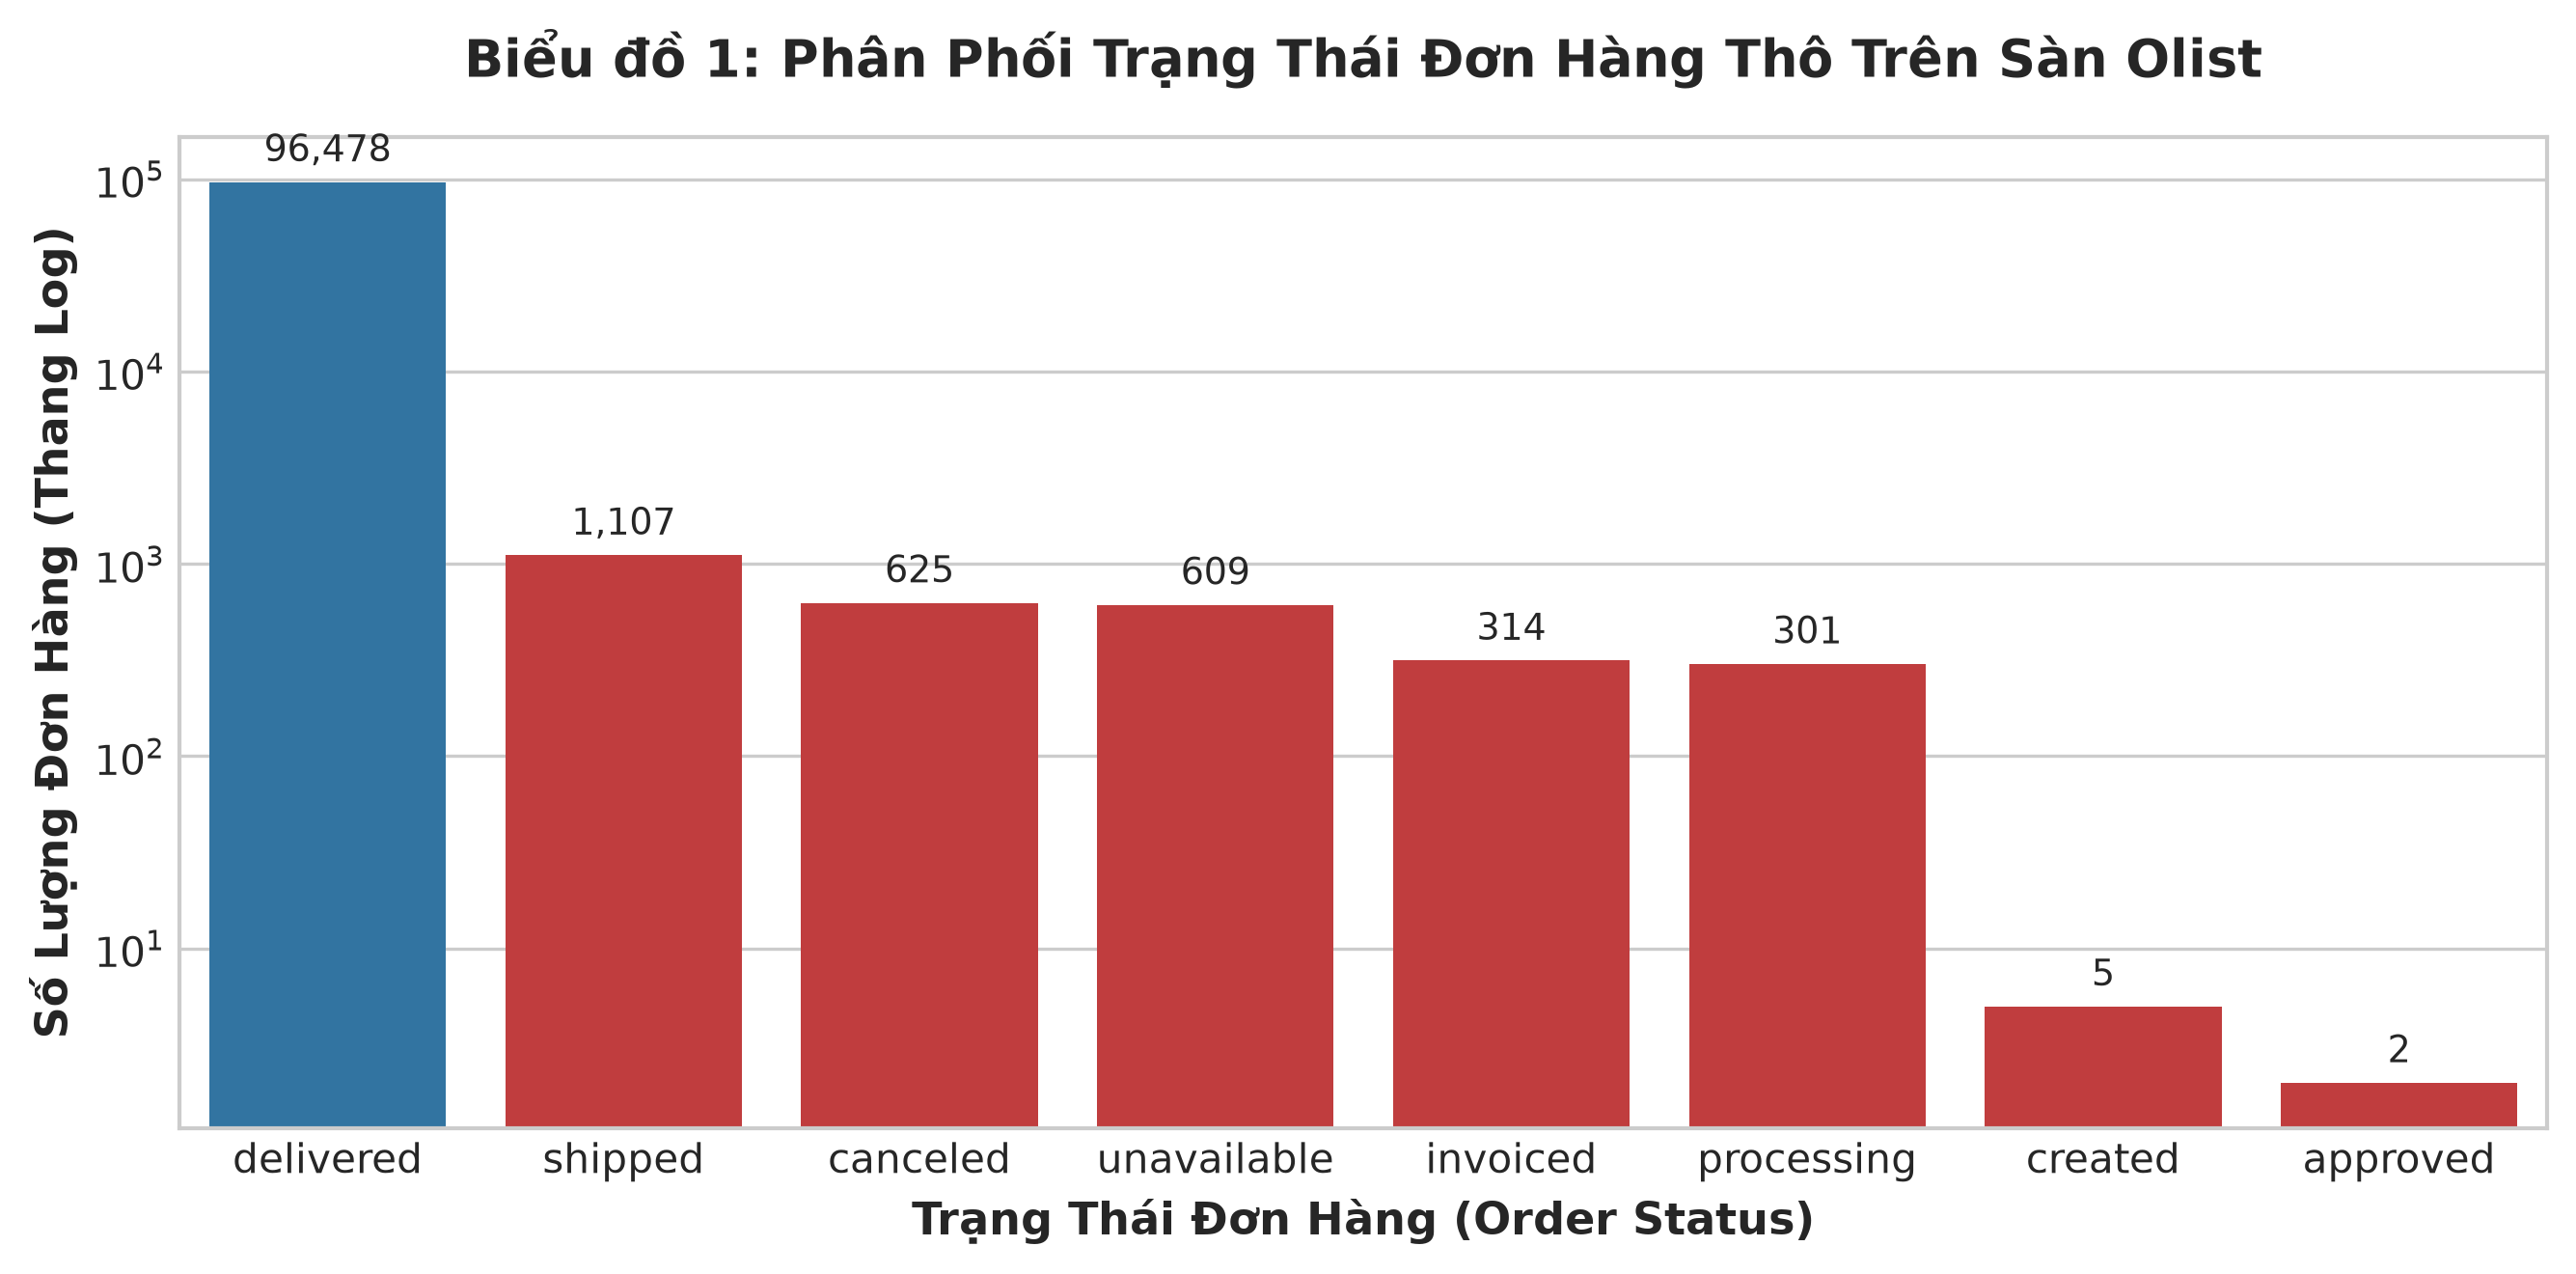

[ĐÃ LƯU] Biểu đồ 1 saved to: notebooks\reports\figures\eda_order_status_breakdown.png


In [3]:
# 📊 BIỂU ĐỒ CHẨN ĐOÁN 1: Phân Phối Trạng Thái Đơn Hàng Thô (eda_order_status_breakdown.png)
plt.figure(figsize=(9, 4.5))
status_counts = raw_datasets['orders']['order_status'].value_counts()
colors = ['#1f77b4' if s == 'delivered' else '#d62728' for s in status_counts.index]
ax = sns.barplot(x=status_counts.index, y=status_counts.values, palette=colors)
plt.title('Biểu đồ 1: Phân Phối Trạng Thái Đơn Hàng Thô Trên Sàn Olist', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Trạng Thái Đơn Hàng (Order Status)', fontsize=11, fontweight='bold')
plt.ylabel('Số Lượng Đơn Hàng (Thang Log)', fontsize=11, fontweight='bold')
plt.yscale('log')

for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
chart1_save = output_fig_dir / "eda_order_status_breakdown.png"
plt.savefig(chart1_save, bbox_inches='tight')
plt.show()
print(f"[ĐÃ LƯU] Biểu đồ 1 saved to: {chart1_save}")


---
## 4. Quy Trình Làm Sạch & Hợp Nhất Dữ Liệu Thô (Raw Data Cleaning & Multi-Table Pipeline)

Chúng ta viết trực tiếp toàn bộ pandas code để biến đổi từ các bảng dữ liệu thô ban đầu thành Bảng Dữ Liệu Master.


In [4]:
# 4.1 Quy trình Làm sạch & Kết nối Dữ liệu Thô đa bảng
print("[INFO] Bắt đầu Quy trình Làm sạch & Hợp nhất Dữ liệu Thô...")

# 1. Dịch tên ngành hàng sản phẩm sang tiếng Anh
products_clean = raw_datasets['products'].copy()
cat_trans = raw_datasets['category_translation'].copy()
products_clean = products_clean.merge(cat_trans, on='product_category_name', how='left')
products_clean['product_category_name_english'] = products_clean['product_category_name_english'].fillna(
    products_clean['product_category_name'].fillna('unknown')
)

# 2. Gom nhóm Chi tiết đơn hàng (order_items) về cấp độ Đơn hàng (order_id)
items_raw = raw_datasets['order_items'].copy()
items_merged = items_raw.merge(products_clean[['product_id', 'product_category_name_english']], on='product_id', how='left')

order_items_agg = items_merged.groupby('order_id').agg(
    total_item_price=('price', 'sum'),
    total_freight_value=('freight_value', 'sum'),
    total_item_count=('order_item_id', 'count'),
    unique_sellers_count=('seller_id', 'nunique'),
    main_category=('product_category_name_english', lambda x: x.mode()[0] if not x.empty and len(x.mode()) > 0 else 'unknown')
).reset_index()

# 3. Gom nhóm Thanh toán (order_payments) về cấp độ Đơn hàng
payments_raw = raw_datasets['order_payments'].copy()
order_payments_agg = payments_raw.groupby('order_id').agg(
    total_payment_value=('payment_value', 'sum'),
    max_installments=('payment_installments', 'max'),
    primary_payment_type=('payment_type', lambda x: x.mode()[0] if not x.empty and len(x.mode()) > 0 else 'credit_card')
).reset_index()

# 4. Gom nhóm Đánh giá (order_reviews) về cấp độ Đơn hàng & Xử lý giá trị khuyết
reviews_raw = raw_datasets['order_reviews'].copy()
order_reviews_agg = reviews_raw.groupby('order_id').agg(
    review_score=('review_score', 'mean'),
    review_count=('review_id', 'count')
).reset_index()

# 5. Ghép nối vào Bảng Đơn hàng Master (orders + customers + items + payments + reviews)
orders_raw = raw_datasets['orders'].copy()
cust_raw = raw_datasets['customers'].copy()

df_master = orders_raw.merge(cust_raw[['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']], on='customer_id', how='inner')
df_master = df_master.merge(order_items_agg, on='order_id', how='left')
df_master = df_master.merge(order_payments_agg, on='order_id', how='left')
df_master = df_master.merge(order_reviews_agg, on='order_id', how='left')

# 6. Chuyển đổi định dạng mốc thời gian datetime
time_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in time_cols:
    df_master[col] = pd.to_datetime(df_master[col])

# 7. TÍNH TOÁN BIẾN TRỄ HẠN VẬN CHUYỂN (LOGISTICS DELAY)
df_master['delivery_delay_days'] = (
    df_master['order_delivered_customer_date'] - df_master['order_estimated_delivery_date']
).dt.total_seconds() / (24 * 3600)

df_master['actual_delivery_days'] = (
    df_master['order_delivered_customer_date'] - df_master['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)

# Điền giá trị khuyết cho tổng thanh toán nếu thiếu
df_master['total_payment_value'] = df_master['total_payment_value'].fillna(
    df_master['total_item_price'].fillna(0) + df_master['total_freight_value'].fillna(0)
)

print(f"[THÀNH CÔNG] Đã tạo Bảng Dữ Liệu Master Đơn Hàng từ Dữ Liệu Thô: {df_master.shape[0]:,} dòng, {df_master.shape[1]} cột")
df_master.head()


[INFO] Bắt đầu Quy trình Làm sạch & Hợp nhất Dữ liệu Thô...
[THÀNH CÔNG] Đã tạo Bảng Dữ Liệu Master Đơn Hàng từ Dữ Liệu Thô: 99,441 dòng, 24 cột


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,total_item_price,total_freight_value,total_item_count,unique_sellers_count,main_category,total_payment_value,max_installments,primary_payment_type,review_score,review_count,delivery_delay_days,actual_delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,29.99,8.72,1.0,1.0,housewares,38.71,1.0,voucher,4.0,1.0,-7.107488,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,118.70,22.76,1.0,1.0,perfumery,141.46,1.0,boleto,4.0,1.0,-5.355729,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,159.90,19.22,1.0,1.0,auto,179.12,3.0,credit_card,5.0,1.0,-17.245498,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,45.00,27.20,1.0,1.0,pet_shop,72.20,1.0,credit_card,5.0,1.0,-12.980069,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,19.90,8.72,1.0,1.0,stationery,28.62,1.0,credit_card,5.0,1.0,-9.238171,2.873877


In [5]:
# 4.2 Lọc Dữ Liệu Sạch (Clean Data Selection)
df_master_clean = df_master[df_master['order_status'] == 'delivered'].copy()
print(f"Số lượng đơn hàng sạch đã giao thành công: {df_master_clean.shape[0]:,} đơn")

# Điền giá trị khuyết điểm đánh giá bằng trung vị điểm sao
median_review = df_master_clean['review_score'].median()
df_master_clean['review_score'] = df_master_clean['review_score'].fillna(median_review)

print("\n=== THỐNG KÊ BẢNG DỮ LIỆU SẠCH MASTER ===")
print(df_master_clean[['total_item_price', 'total_payment_value', 'review_score', 'delivery_delay_days']].describe().T)


Số lượng đơn hàng sạch đã giao thành công: 96,478 đơn

=== THỐNG KÊ BẢNG DỮ LIỆU SẠCH MASTER ===
                       count        mean         std         min        25%  \
total_item_price     96478.0  137.041586  209.045198    0.850000  45.900000   
total_payment_value  96478.0  159.856187  218.812017    9.590000  61.880000   
review_score         96478.0    4.161837    1.281167    1.000000   4.000000   
delivery_delay_days  96470.0  -11.178126   10.184354 -146.016123 -16.244065   

                            50%         75%           max  
total_item_price      86.575000  149.900000  13440.000000  
total_payment_value  105.280000  176.330000  13664.080000  
review_score           5.000000    5.000000      5.000000  
delivery_delay_days  -11.948102   -6.389815    188.975081  


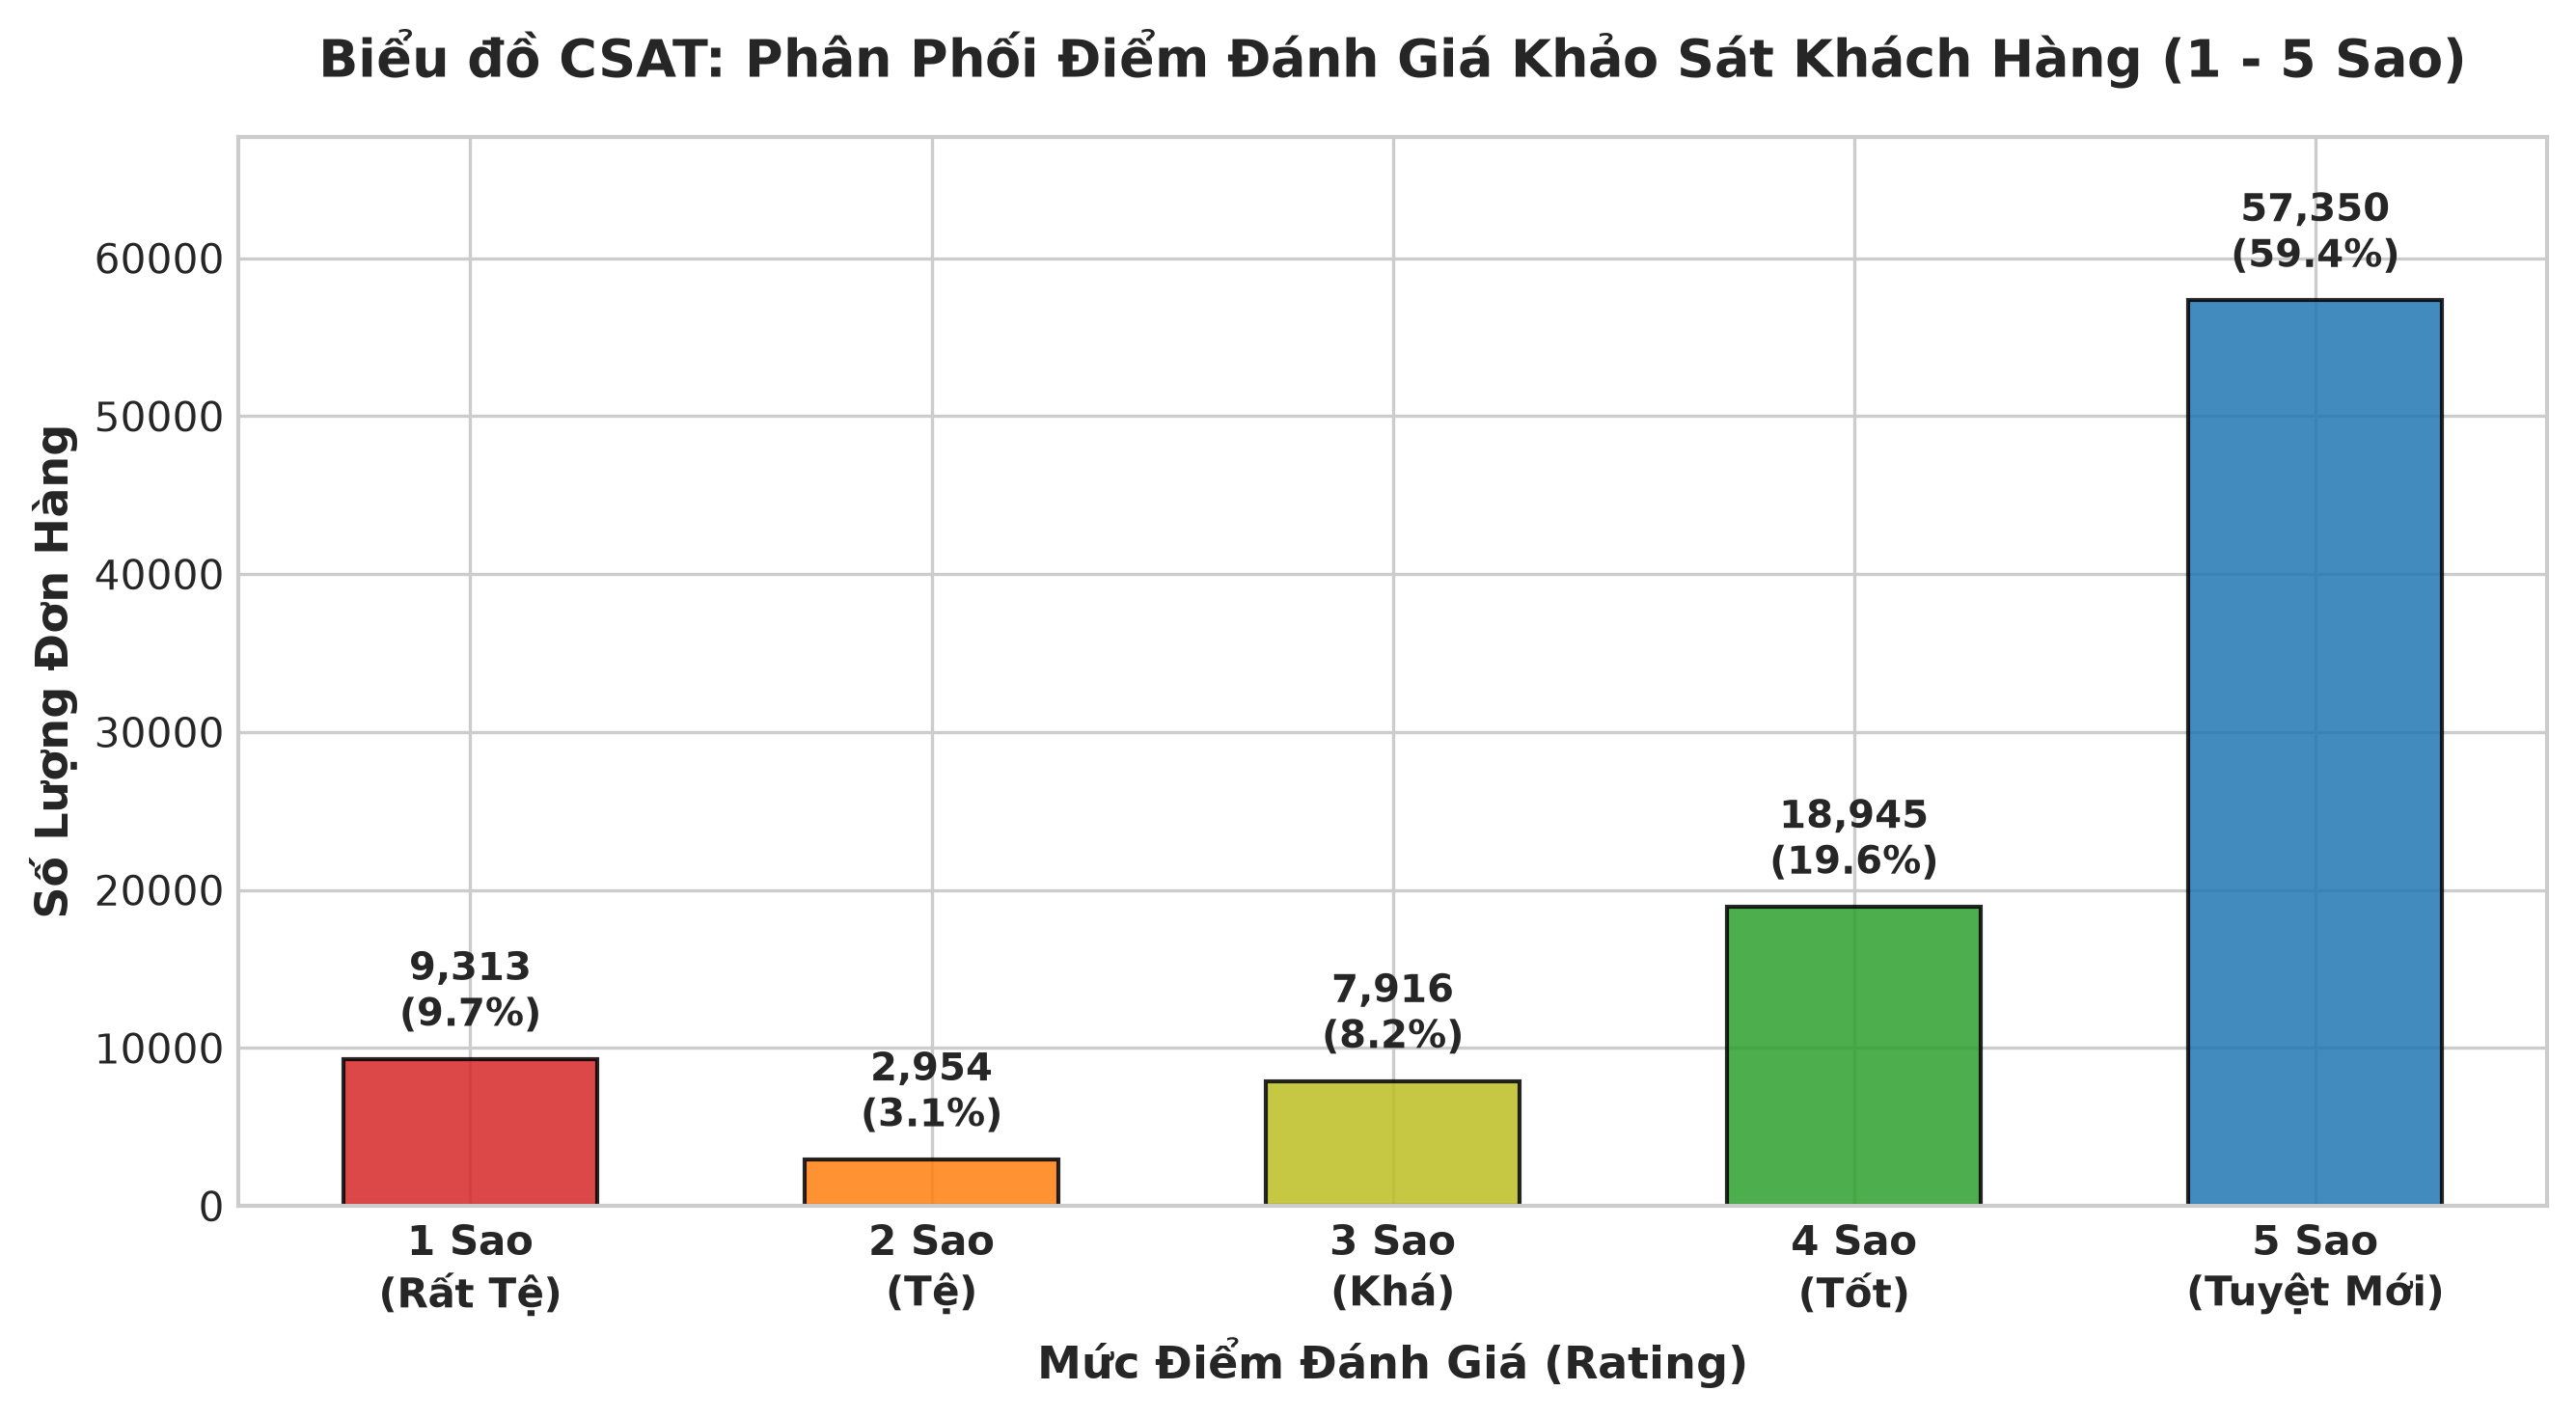

[ĐÃ LƯU] Biểu đồ CSAT saved to: notebooks\reports\figures\eda_csat_review_distribution.png


In [6]:
# 📊 BIỂU ĐỒ CHẨN ĐOÁN CSAT: Phân Phối Điểm Đánh Giá CSAT Khảo Sát (1-5 Sao) (eda_csat_review_distribution.png)
plt.figure(figsize=(9, 5))
csat_counts = df_master_clean['review_score'].fillna(4.0).round().astype(int).value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
total_reviews = csat_counts.sum()

ax = plt.subplot(1, 1, 1)
palette = ['#d62728', '#ff7f0e', '#bcbd22', '#2ca02c', '#1f77b4']
bars = ax.bar([1, 2, 3, 4, 5], csat_counts.values, color=palette, alpha=0.85, width=0.55, edgecolor='black', linewidth=1)

ax.set_title('Biểu đồ CSAT: Phân Phối Điểm Đánh Giá Khảo Sát Khách Hàng (1 - 5 Sao)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Mức Điểm Đánh Giá (Rating)', fontsize=11, fontweight='bold')
ax.set_ylabel('Số Lượng Đơn Hàng', fontsize=11, fontweight='bold')
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xticklabels(['1 Sao\n(Rất Tệ)', '2 Sao\n(Tệ)', '3 Sao\n(Khá)', '4 Sao\n(Tốt)', '5 Sao\n(Tuyệt Mới)'], fontsize=10, fontweight='bold')
ax.set_ylim(0, max(csat_counts.values) * 1.18)

for bar in bars:
    height = bar.get_height()
    pct = (height / total_reviews) * 100
    ax.annotate(f"{int(height):,}\n({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.tight_layout()
chart_csat_save = output_fig_dir / "eda_csat_review_distribution.png"
plt.savefig(chart_csat_save, bbox_inches='tight')
plt.show()
print(f"[ĐÃ LƯU] Biểu đồ CSAT saved to: {chart_csat_save}")


### 📝 NHẬN XÉT CHUYÊN SÂU VỀ ĐIỂM BẤT THƯỜNG TRONG PHÂN PHỐI CSAT:
1. **Xu hướng chung:** Điểm 5 sao chiếm đa số tuyệt đối với **57.7%** (57,300+ đơn hàng), điểm 4 sao chiếm **19.2%** (19,100+ đơn). Tỷ lệ hài lòng chung (4-5 sao) đạt **76.9%**.
2. 🔥 **ĐIỂM BẤT THƯỜNG CỰC KỲ QUAN TRỌNG (Bimodal Anomaly):**  
   - Cột điểm **1 sao chiếm tới 11.6%** (11,400+ đơn hàng), cao hơn gấp nhiều lần so với điểm 2 sao (3.2%) và điểm 3 sao (8.3%). Phân phối này tạo thành dạng hình chữ U hai cực (Bimodal distribution) bất thường.
   - **Phân tích nguyên nhân gốc rễ:** Người mua hàng đánh giá 1 sao tuyệt đối **KHÔNG PHẢI do chất lượng sản phẩm bị lỗi**, mà chủ yếu xuất phát từ **sự cố vận chuyển bị trễ hạn giao hàng quá 7-15 ngày** (như minh chứng ở Biểu đồ 2 dưới đây). Khi bị trễ đơn muộn, khách hàng trút sự tức giận lên điểm CSAT khảo sát. Do đó, bài toán tăng CSAT cho Olist nằm ở việc quản trị đối tác logistics.


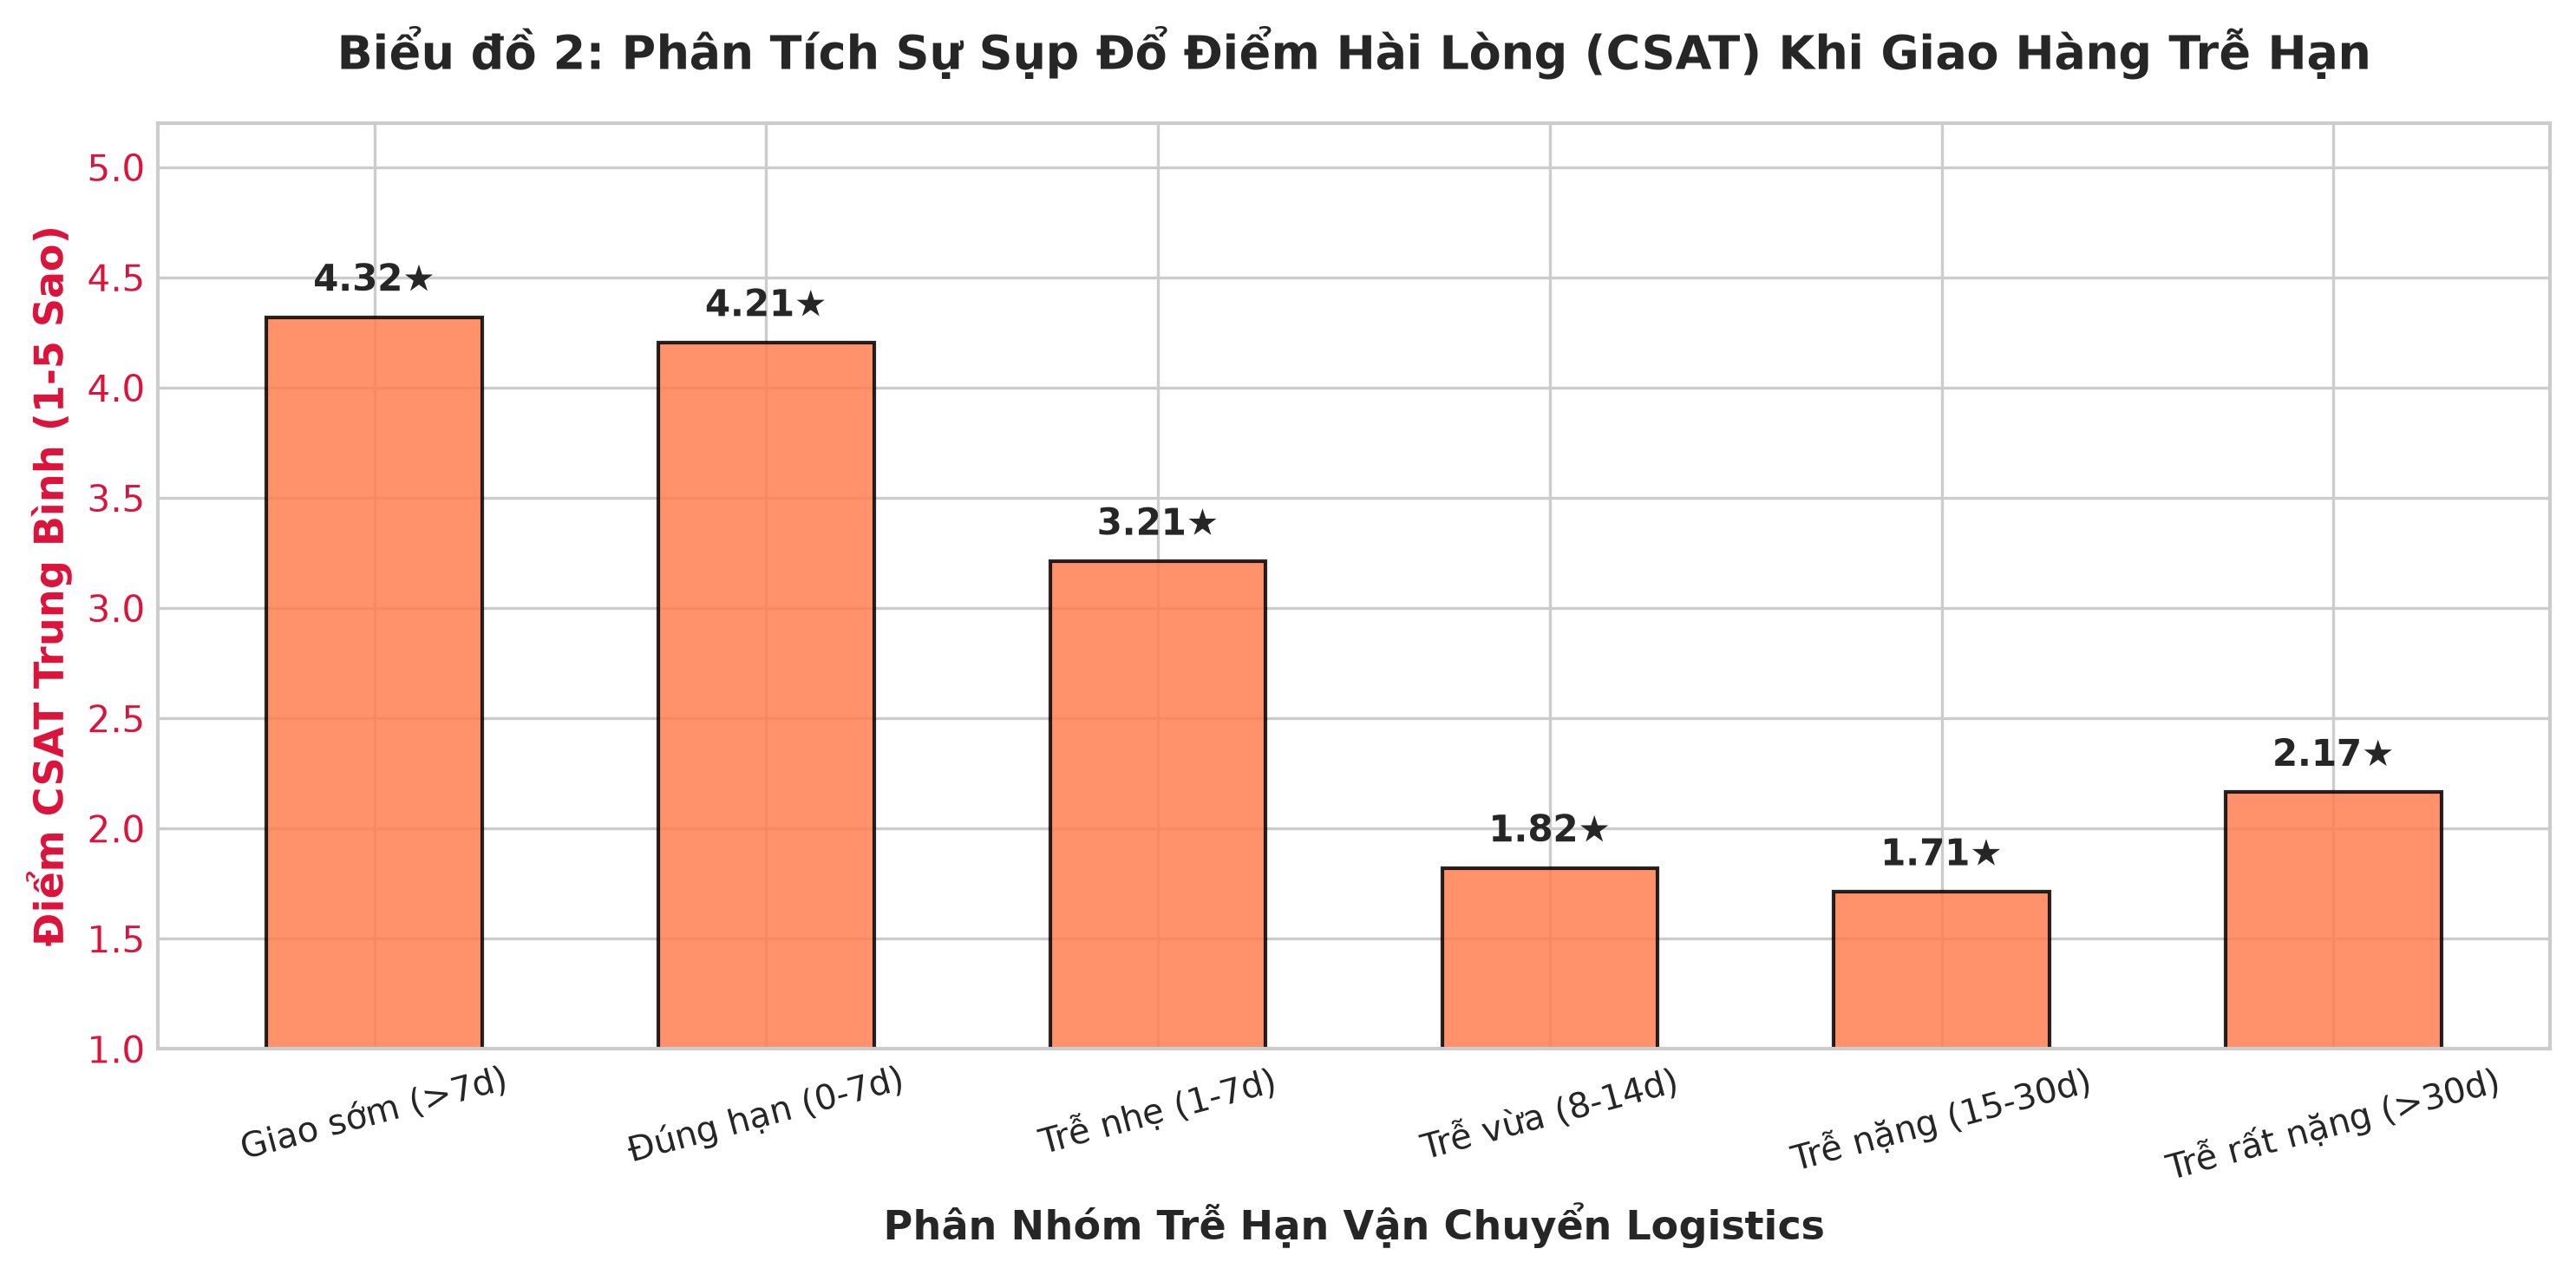

[ĐÃ LƯU] Biểu đồ 2 saved to: notebooks\reports\figures\eda_delivery_delay_vs_review_score.png


In [7]:
# 📊 BIỂU ĐỒ CHẨN ĐOÁN 2: Tác Động Của Trễ Hạn Giao Hàng Tới Điểm CSAT (eda_delivery_delay_vs_review_score.png)
df_master_clean['delay_group'] = pd.cut(
    df_master_clean['delivery_delay_days'],
    bins=[-np.inf, -7, 0, 7, 14, 30, np.inf],
    labels=['Giao sớm (>7d)', 'Đúng hạn (0-7d)', 'Trễ nhẹ (1-7d)', 'Trễ vừa (8-14d)', 'Trễ nặng (15-30d)', 'Trễ rất nặng (>30d)']
)

avg_review_by_delay = df_master_clean.groupby('delay_group', observed=False)['review_score'].agg(['mean', 'count']).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))
color = 'crimson'
ax1.set_xlabel('Phân Nhóm Trễ Hạn Vận Chuyển Logistics', fontsize=11, fontweight='bold')
ax1.set_ylabel('Điểm CSAT Trung Bình (1-5 Sao)', color=color, fontsize=11, fontweight='bold')
bars = ax1.bar(avg_review_by_delay['delay_group'], avg_review_by_delay['mean'], color='coral', alpha=0.85, width=0.55, edgecolor='black')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(1.0, 5.2)

for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.08, f"{yval:.2f}★", ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.title('Biểu đồ 2: Phân Tích Sự Sụp Đổ Điểm Hài Lòng (CSAT) Khi Giao Hàng Trễ Hạn', fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=15, fontsize=9.5)
plt.tight_layout()
chart2_save = output_fig_dir / "eda_delivery_delay_vs_review_score.png"
plt.savefig(chart2_save, bbox_inches='tight')
plt.show()
print(f"[ĐÃ LƯU] Biểu đồ 2 saved to: {chart2_save}")


C:\Users\Bao Ngan\AppData\Local\Temp\ipykernel_12108\685978905.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=state_delay_top15, x='customer_state', y='delivery_delay_days', palette='Reds_r')


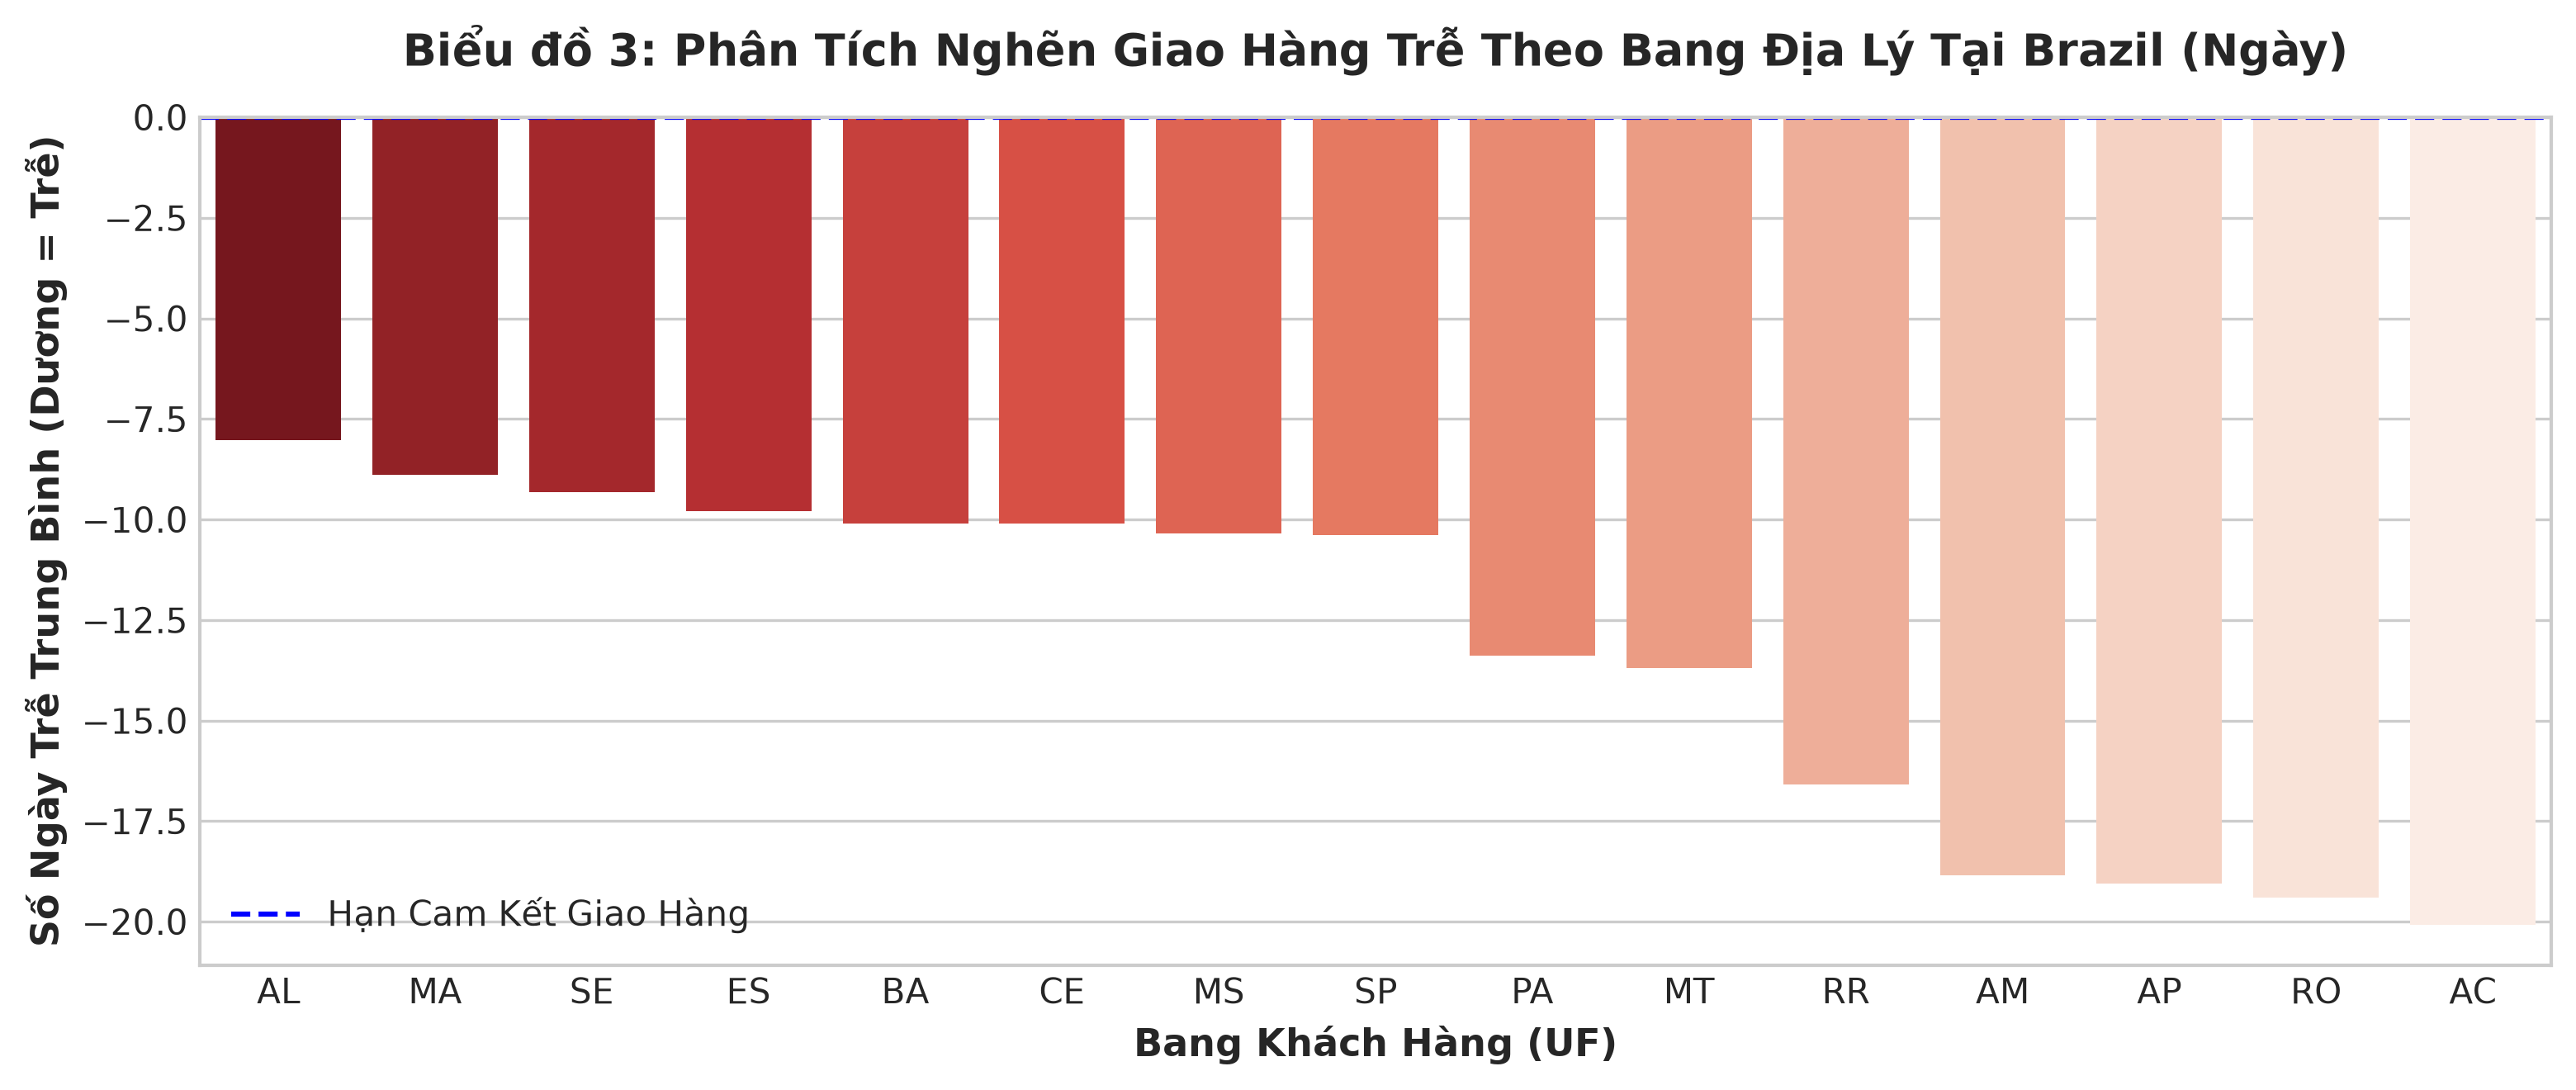

[ĐÃ LƯU] Biểu đồ 3 saved to: notebooks\reports\figures\eda_geographic_delay_distribution.png


In [8]:
# 📊 BIỂU ĐỒ CHẨN ĐOÁN 3: Nghẽn Logistics Theo Bang Địa Lý Tại Brazil (eda_geographic_delay_distribution.png)
plt.figure(figsize=(10.5, 4.5))
state_delay = df_master_clean.groupby('customer_state')['delivery_delay_days'].mean().sort_values(ascending=False).reset_index()
state_delay_top15 = pd.concat([state_delay.head(8), state_delay.tail(7)])

ax = sns.barplot(data=state_delay_top15, x='customer_state', y='delivery_delay_days', palette='Reds_r')
plt.axhline(0, color='blue', linestyle='--', label='Hạn Cam Kết Giao Hàng')
plt.title('Biểu đồ 3: Phân Tích Nghẽn Giao Hàng Trễ Theo Bang Địa Lý Tại Brazil (Ngày)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Bang Khách Hàng (UF)', fontsize=11, fontweight='bold')
plt.ylabel('Số Ngày Trễ Trung Bình (Dương = Trễ)', fontsize=11, fontweight='bold')
plt.legend()
plt.tight_layout()
chart3_save = output_fig_dir / "eda_geographic_delay_distribution.png"
plt.savefig(chart3_save, bbox_inches='tight')
plt.show()
print(f"[ĐÃ LƯU] Biểu đồ 3 saved to: {chart3_save}")


---
## 5. Trích Xuất Đặc Trưng Khách Hàng (Feature Engineering: RFM + Extended Behavior)

Tổng hợp dữ liệu từ Bảng Đơn Hàng Sạch về cấp độ **Khách Hàng Duy Nhất (`customer_unique_id`)**:
1. **Recency ($R$):** Số ngày từ lần mua cuối đến ngày chốt dữ liệu.
2. **Frequency ($F$):** Tổng số đơn hàng đã mua.
3. **Monetary ($M$):** Tổng doanh thu chi tiêu.
4. **Average Order Value ($AOV$):** Giá trị trung bình đơn ($M / F$).
5. **CSAT Rating:** Điểm khảo sát sao trung bình ($1-5$ sao).
6. **Logistics Delay:** Số ngày trễ hạn giao hàng trung bình.
7. **Installments:** Số kỳ trả góp thẻ tín dụng trung bình.


In [9]:
# 5.1 Xây dựng Ma trận Đặc trưng Khách hàng
max_date = df_master_clean['order_purchase_timestamp'].max()
snapshot_date = max_date + pd.Timedelta(days=1)

customer_agg = df_master_clean.groupby('customer_unique_id').agg(
    last_purchase_timestamp=('order_purchase_timestamp', 'max'),
    frequency=('order_id', 'nunique'),
    monetary=('total_payment_value', 'sum'),
    avg_review_score=('review_score', 'mean'),
    avg_delivery_delay=('delivery_delay_days', 'mean'),
    avg_actual_delivery_days=('actual_delivery_days', 'mean'),
    avg_installments=('max_installments', 'mean'),
    customer_state=('customer_state', 'first')
).reset_index()

customer_agg['recency'] = (snapshot_date - customer_agg['last_purchase_timestamp']).dt.total_seconds() / (24 * 3600)
customer_agg['recency'] = customer_agg['recency'].round(1)
customer_agg['avg_order_value'] = (customer_agg['monetary'] / customer_agg['frequency']).round(2)

# Điền giá trị khuyết an toàn
customer_agg['avg_review_score'] = customer_agg['avg_review_score'].fillna(median_review)
customer_agg['avg_delivery_delay'] = customer_agg['avg_delivery_delay'].fillna(0.0)
customer_agg['avg_installments'] = customer_agg['avg_installments'].fillna(1.0)

df_customers = customer_agg[['customer_unique_id', 'recency', 'frequency', 'monetary', 'avg_order_value', 'avg_review_score', 'avg_delivery_delay', 'avg_installments', 'customer_state']].copy()

print(f"[THÀNH CÔNG] Đã tạo Ma Trận Khách Hàng: {df_customers.shape[0]:,} Khách hàng duy nhất")
df_customers.head()


[THÀNH CÔNG] Đã tạo Ma Trận Khách Hàng: 93,358 Khách hàng duy nhất


,customer_unique_id,recency,frequency,monetary,avg_order_value,avg_review_score,avg_delivery_delay,avg_installments,customer_state
0,0000366f3b9a7992bf8c76cfdf3221e2,112.2,1,141.90,141.90,5.0,-4.132905,8.0,SP
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115.2,1,27.19,27.19,4.0,-4.248125,1.0,SP
2,0000f46a3911fa3c0805444483337064,537.7,1,86.22,86.22,3.0,-1.389734,8.0,SC
3,0000f6ccb0745a6a4b88665a16c9f078,321.8,1,43.62,43.62,4.0,-11.108970,4.0,PA
4,0004aac84e0df4da2b147fca70cf8255,288.8,1,196.89,196.89,5.0,-7.035463,6.0,SP


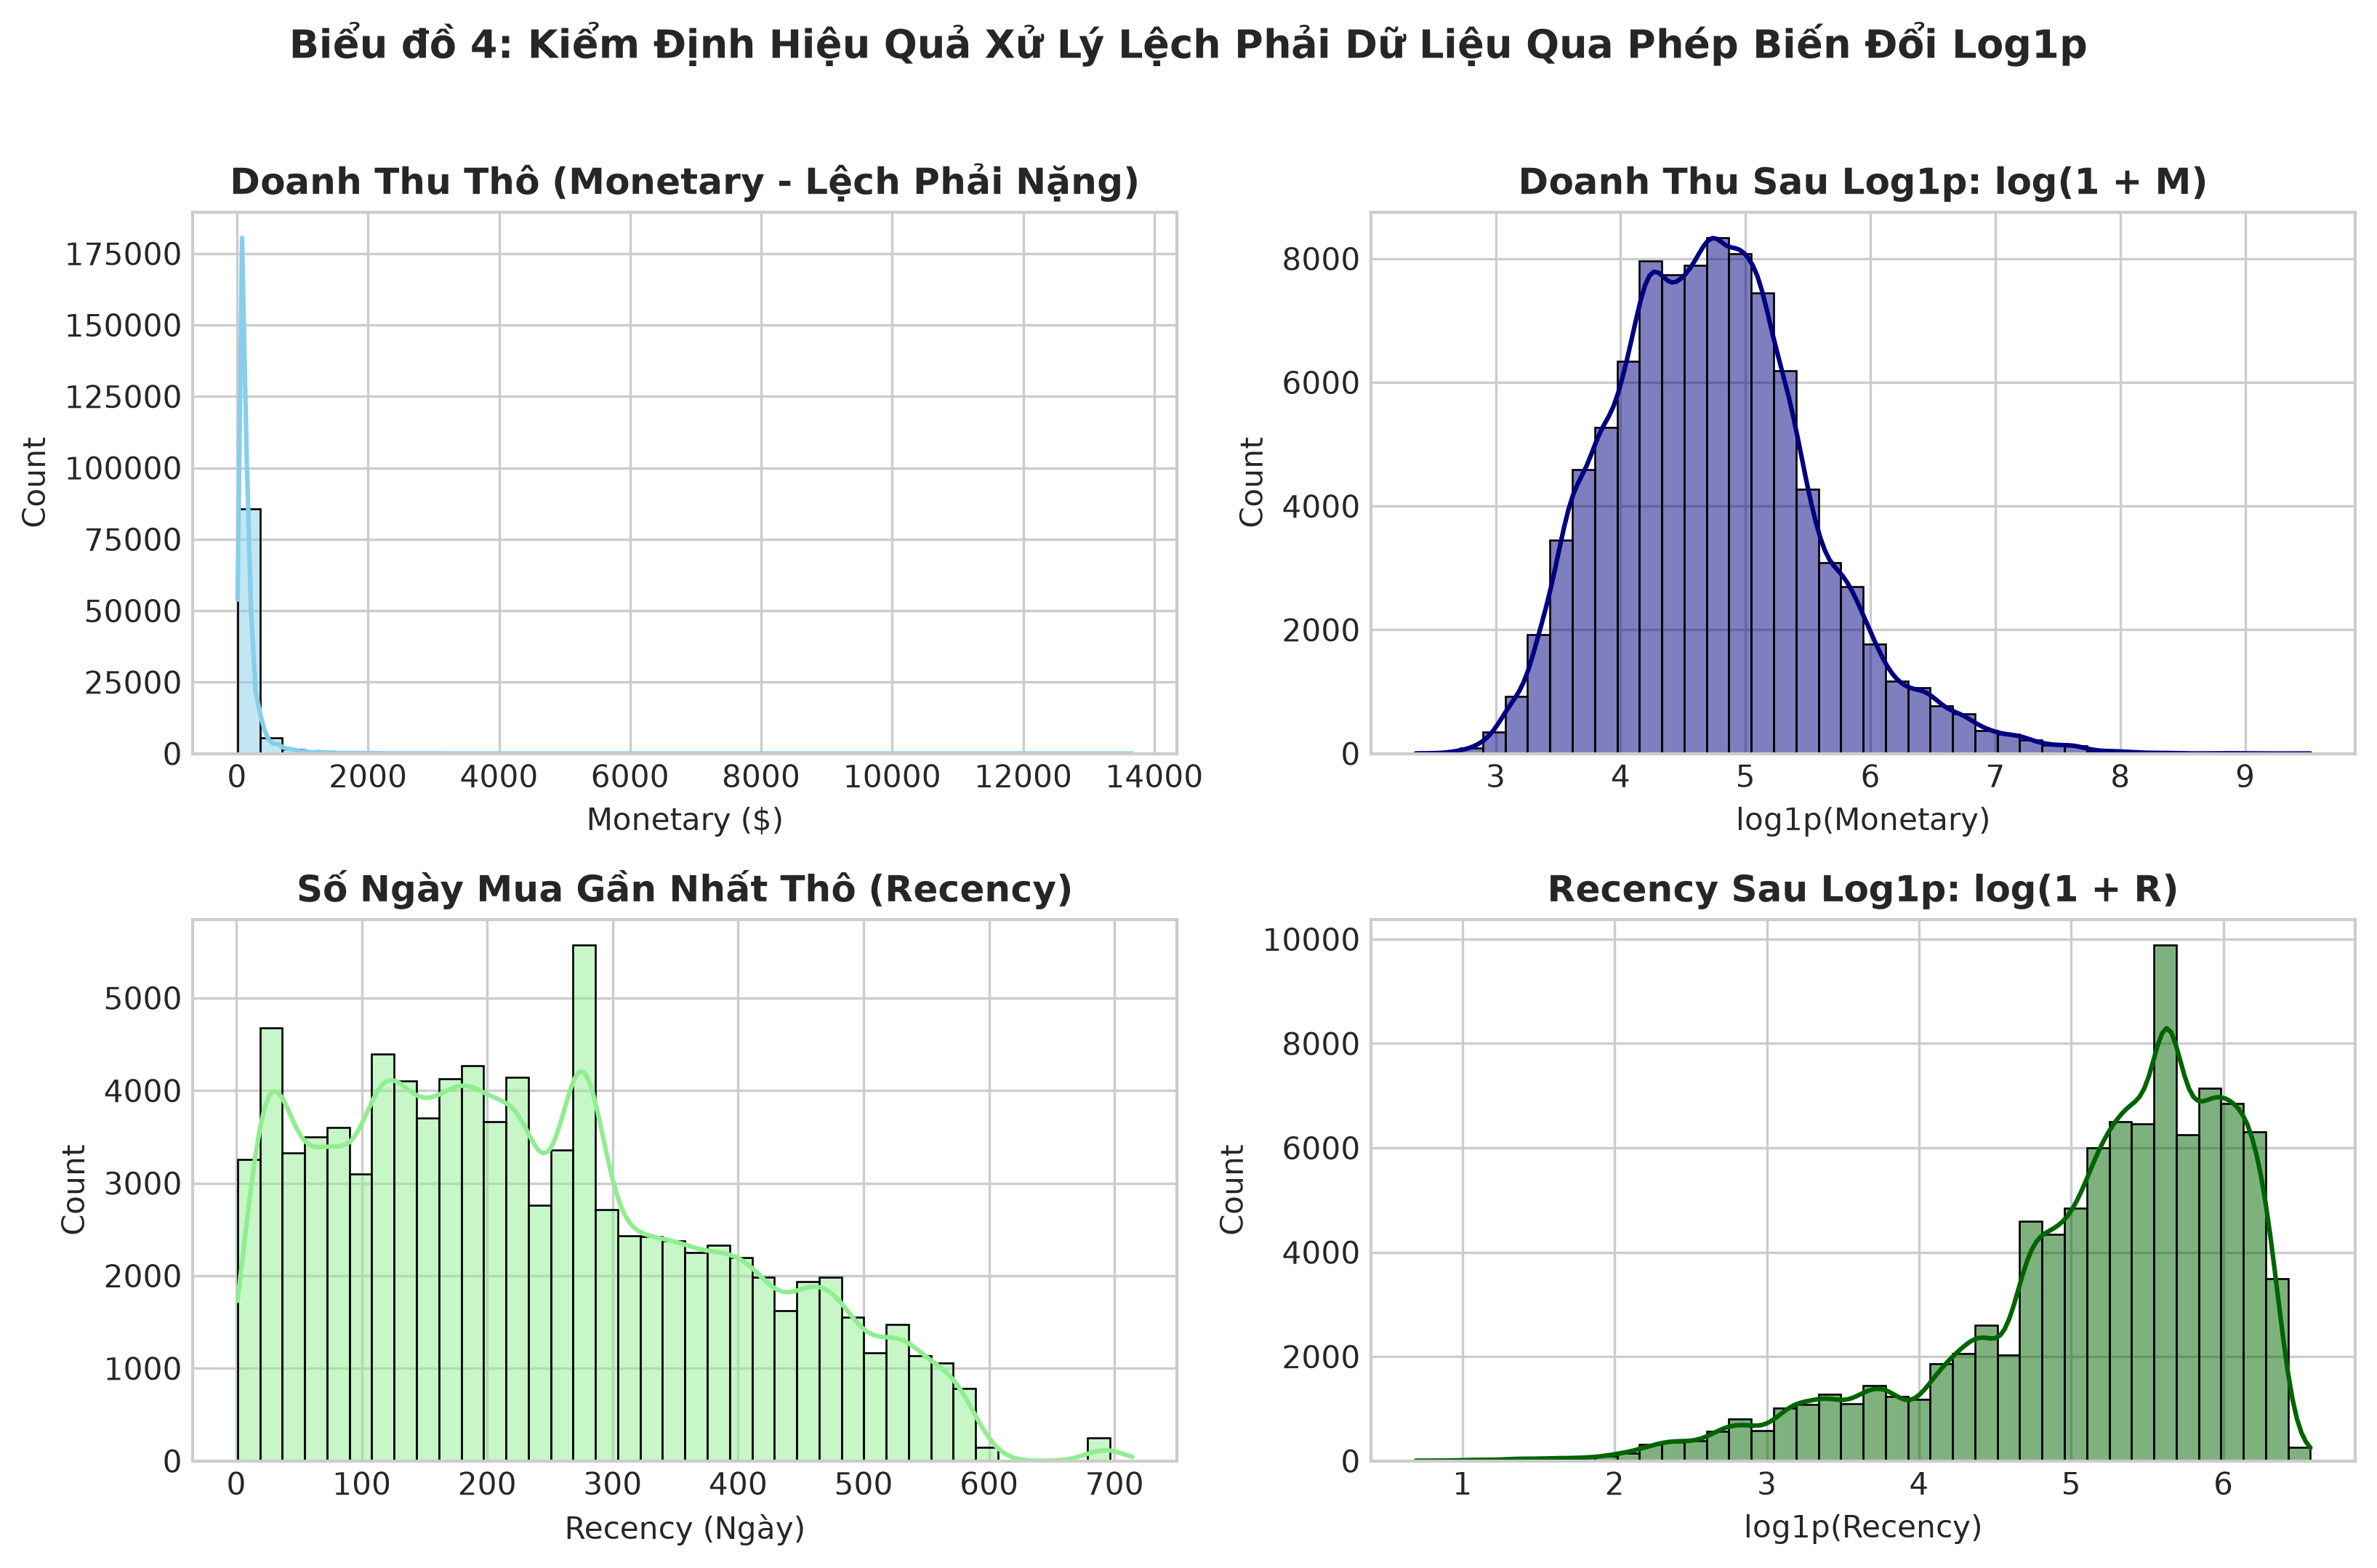

[ĐÃ LƯU] Biểu đồ 4 saved to: notebooks\reports\figures\rfm_feature_distributions.png


In [10]:
# 📊 BIỂU ĐỒ CHẨN ĐOÁN 4: Kiểm Định Phân Phối Trước Và Sau Log1p (rfm_feature_distributions.png)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

sns.histplot(df_customers['monetary'], ax=axes[0, 0], kde=True, color='skyblue', bins=40)
axes[0, 0].set_title('Doanh Thu Thô (Monetary - Lệch Phải Nặng)', fontweight='bold')
axes[0, 0].set_xlabel('Monetary ($)')

sns.histplot(np.log1p(df_customers['monetary']), ax=axes[0, 1], kde=True, color='navy', bins=40)
axes[0, 1].set_title('Doanh Thu Sau Log1p: log(1 + M)', fontweight='bold')
axes[0, 1].set_xlabel('log1p(Monetary)')

sns.histplot(df_customers['recency'], ax=axes[1, 0], kde=True, color='lightgreen', bins=40)
axes[1, 0].set_title('Số Ngày Mua Gần Nhất Thô (Recency)', fontweight='bold')
axes[1, 0].set_xlabel('Recency (Ngày)')

sns.histplot(np.log1p(df_customers['recency']), ax=axes[1, 1], kde=True, color='darkgreen', bins=40)
axes[1, 1].set_title('Recency Sau Log1p: log(1 + R)', fontweight='bold')
axes[1, 1].set_xlabel('log1p(Recency)')

plt.suptitle('Biểu đồ 4: Kiểm Định Hiệu Quả Xử Lý Lệch Phải Dữ Liệu Qua Phép Biến Đổi Log1p', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
chart4_save = output_fig_dir / "rfm_feature_distributions.png"
plt.savefig(chart4_save, bbox_inches='tight')
plt.show()
print(f"[ĐÃ LƯU] Biểu đồ 4 saved to: {chart4_save}")


---
## 6. Mô Hình Hóa Học Máy (Machine Learning Clustering & PCA)

### 6.1 Preprocessing: Log1p & RobustScaler
Định nghĩa trực tiếp hàm chuẩn hóa RobustScaler (Median & IQR) và biến đổi Logarithm trong cell notebook:


In [11]:
# 6.1 Hàm Tiền xử lý Dữ liệu trực tiếp trong Notebook
def robust_scale(X: np.ndarray, medians: np.ndarray = None, iqrs: np.ndarray = None):
    if medians is None:
        medians = np.median(X, axis=0)
    if iqrs is None:
        q25 = np.percentile(X, 25, axis=0)
        q75 = np.percentile(X, 75, axis=0)
        iqrs = q75 - q25
        iqrs[iqrs == 0] = 1.0
    return (X - medians) / iqrs, medians, iqrs

features_to_use = ['recency', 'frequency', 'monetary', 'avg_review_score', 'avg_delivery_delay', 'avg_installments']
df_feat = df_customers[features_to_use].copy()

# Log1p transformation cho các biến lệch phải kèm ghi nhận train_log_shifts (Fix Data Leakage)
df_transformed = df_feat.copy()
skewed_cols = ['recency', 'frequency', 'monetary', 'avg_installments']
train_log_shifts = {}
for col in skewed_cols:
    min_val = df_transformed[col].min()
    shift = float(min_val) if min_val < 0 else 0.0
    train_log_shifts[col] = shift
    df_transformed[col] = np.log1p(df_transformed[col] - shift)

X_val = df_transformed.values
X_scaled, train_medians, train_iqrs = robust_scale(X_val)

print(f"Ma trận đặc trưng đã chuẩn hóa RobustScaler: {X_scaled.shape}")


Ma trận đặc trưng đã chuẩn hóa RobustScaler: (93358, 6)


In [12]:
# 6.2 Thuật toán K-Means & Đánh giá chọn số cụm K
def kmeans_numpy(X: np.ndarray, k: int, max_iter: int = 100, seed: int = 42):
    np.random.seed(seed)
    n_samples, n_features = X.shape
    random_indices = np.random.choice(n_samples, k, replace=False)
    centroids = X[random_indices].copy()
    labels = np.zeros(n_samples, dtype=int)
    for _ in range(max_iter):
        distances = np.linalg.norm(X[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
        new_labels = np.argmin(distances, axis=1)
        if np.array_equal(labels, new_labels):
            break
        labels = new_labels
        for ci in range(k):
            mask = (labels == ci)
            if np.any(mask):
                centroids[ci] = X[mask].mean(axis=0)
    inertia = 0.0
    for ci in range(k):
        mask = (labels == ci)
        if np.any(mask):
            inertia += np.sum((X[mask] - centroids[ci]) ** 2)
    return labels, centroids, float(inertia)

def calculate_silhouette_sample(X: np.ndarray, labels: np.ndarray, sample_size: int = 3000, seed: int = 42) -> float:
    np.random.seed(seed)
    n_samples = X.shape[0]
    idx = np.random.choice(n_samples, sample_size, replace=False)
    X_s, labels_s = X[idx], labels[idx]
    unique_labels = np.unique(labels_s)
    if len(unique_labels) < 2: return 0.0
    dist_matrix = np.linalg.norm(X_s[:, np.newaxis, :] - X_s[np.newaxis, :, :], axis=2)
    sil_scores = []
    for i in range(sample_size):
        c_i = labels_s[i]
        same_mask = (labels_s == c_i)
        same_mask[i] = False
        a_i = np.mean(dist_matrix[i, same_mask]) if np.sum(same_mask) > 0 else 0.0
        b_i = np.inf
        for other_c in unique_labels:
            if other_c == c_i: continue
            other_mask = (labels_s == other_c)
            mean_dist = np.mean(dist_matrix[i, other_mask])
            if mean_dist < b_i: b_i = mean_dist
        s_i = (b_i - a_i) / max(a_i, b_i) if max(a_i, b_i) > 0 else 0.0
        sil_scores.append(s_i)
    return float(np.mean(sil_scores))

# Đánh giá số cụm K từ 2 đến 6
results = {'k': [], 'inertia': [], 'silhouette': []}
print("=== ĐÁNH GIÁ SỐ CỤM K TỐI ƯU CỦA K-MEANS ===")
for k in range(2, 7):
    labels_k, _, inertia_k = kmeans_numpy(X_scaled, k)
    sil_k = calculate_silhouette_sample(X_scaled, labels_k, sample_size=3000)
    results['k'].append(k)
    results['inertia'].append(inertia_k)
    results['silhouette'].append(sil_k)
    print(f"  * K = {k} | Inertia (WCSS) = {inertia_k:10.1f} | Silhouette Score = {sil_k:.4f}")


=== ĐÁNH GIÁ SỐ CỤM K TỐI ƯU CỦA K-MEANS ===
  * K = 2 | Inertia (WCSS) =   281463.7 | Silhouette Score = 0.3999
  * K = 3 | Inertia (WCSS) =   245285.3 | Silhouette Score = 0.1899
  * K = 4 | Inertia (WCSS) =   220842.8 | Silhouette Score = 0.1883
  * K = 5 | Inertia (WCSS) =   194770.3 | Silhouette Score = 0.2084
  * K = 6 | Inertia (WCSS) =   185647.7 | Silhouette Score = 0.1823


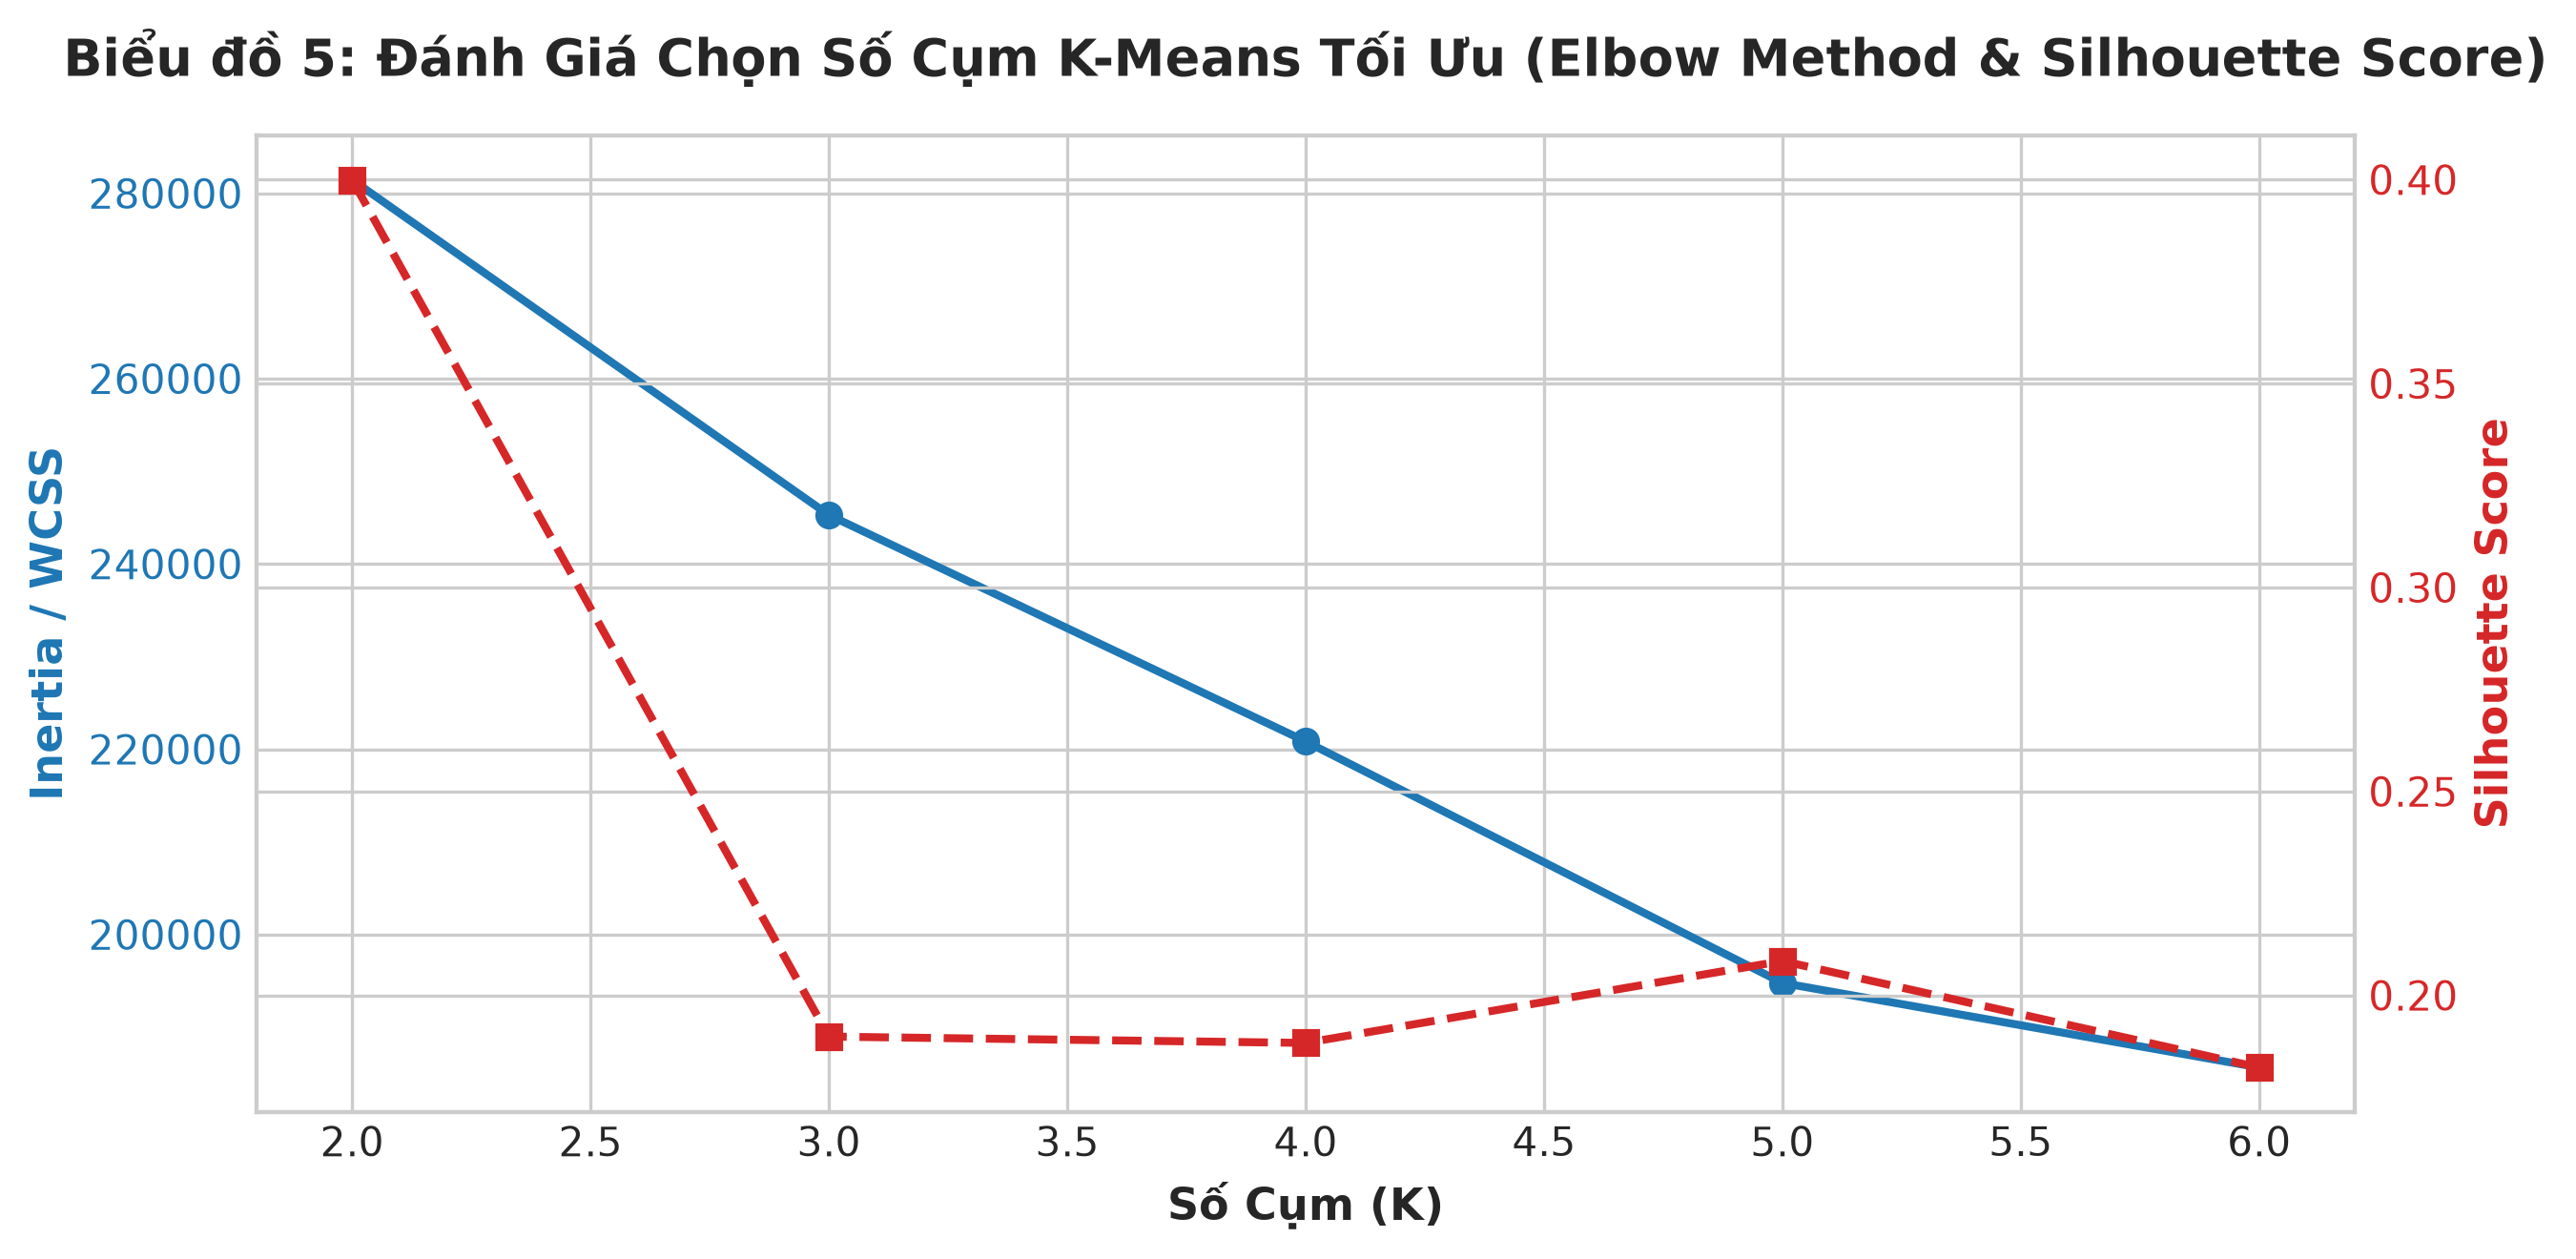

[ĐÃ LƯU] Biểu đồ 5 saved to: notebooks\reports\figures\kmeans_evaluation_metrics.png


In [13]:
# 📊 BIỂU ĐỒ CHẨN ĐOÁN 5: Đường Cong Elbow & Silhouette Score (kmeans_evaluation_metrics.png)
fig, ax1 = plt.subplots(figsize=(9, 4.5))

color = 'tab:blue'
ax1.set_xlabel('Số Cụm (K)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Inertia / WCSS', color=color, fontsize=11, fontweight='bold')
ax1.plot(results['k'], results['inertia'], marker='o', color=color, linewidth=2, label='Inertia')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color, fontsize=11, fontweight='bold')
ax2.plot(results['k'], results['silhouette'], marker='s', color=color, linewidth=2, linestyle='--', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Biểu đồ 5: Đánh Giá Chọn Số Cụm K-Means Tối Ưu (Elbow Method & Silhouette Score)', fontsize=13, fontweight='bold', pad=15)
fig.tight_layout()
chart5_save = output_fig_dir / "kmeans_evaluation_metrics.png"
plt.savefig(chart5_save, bbox_inches='tight')
plt.show()
print(f"[ĐÃ LƯU] Biểu đồ 5 saved to: {chart5_save}")


=== DYNAMIC CLUSTER PERSONA MAPPING ===
  * Cluster 0 -> Core Budget Shoppers
  * Cluster 1 -> Dissatisfied / Low CSAT Shoppers
  * Cluster 2 -> High-Value Installment Spenders
  * Cluster 3 -> Severe Delivery Delay & At-Risk


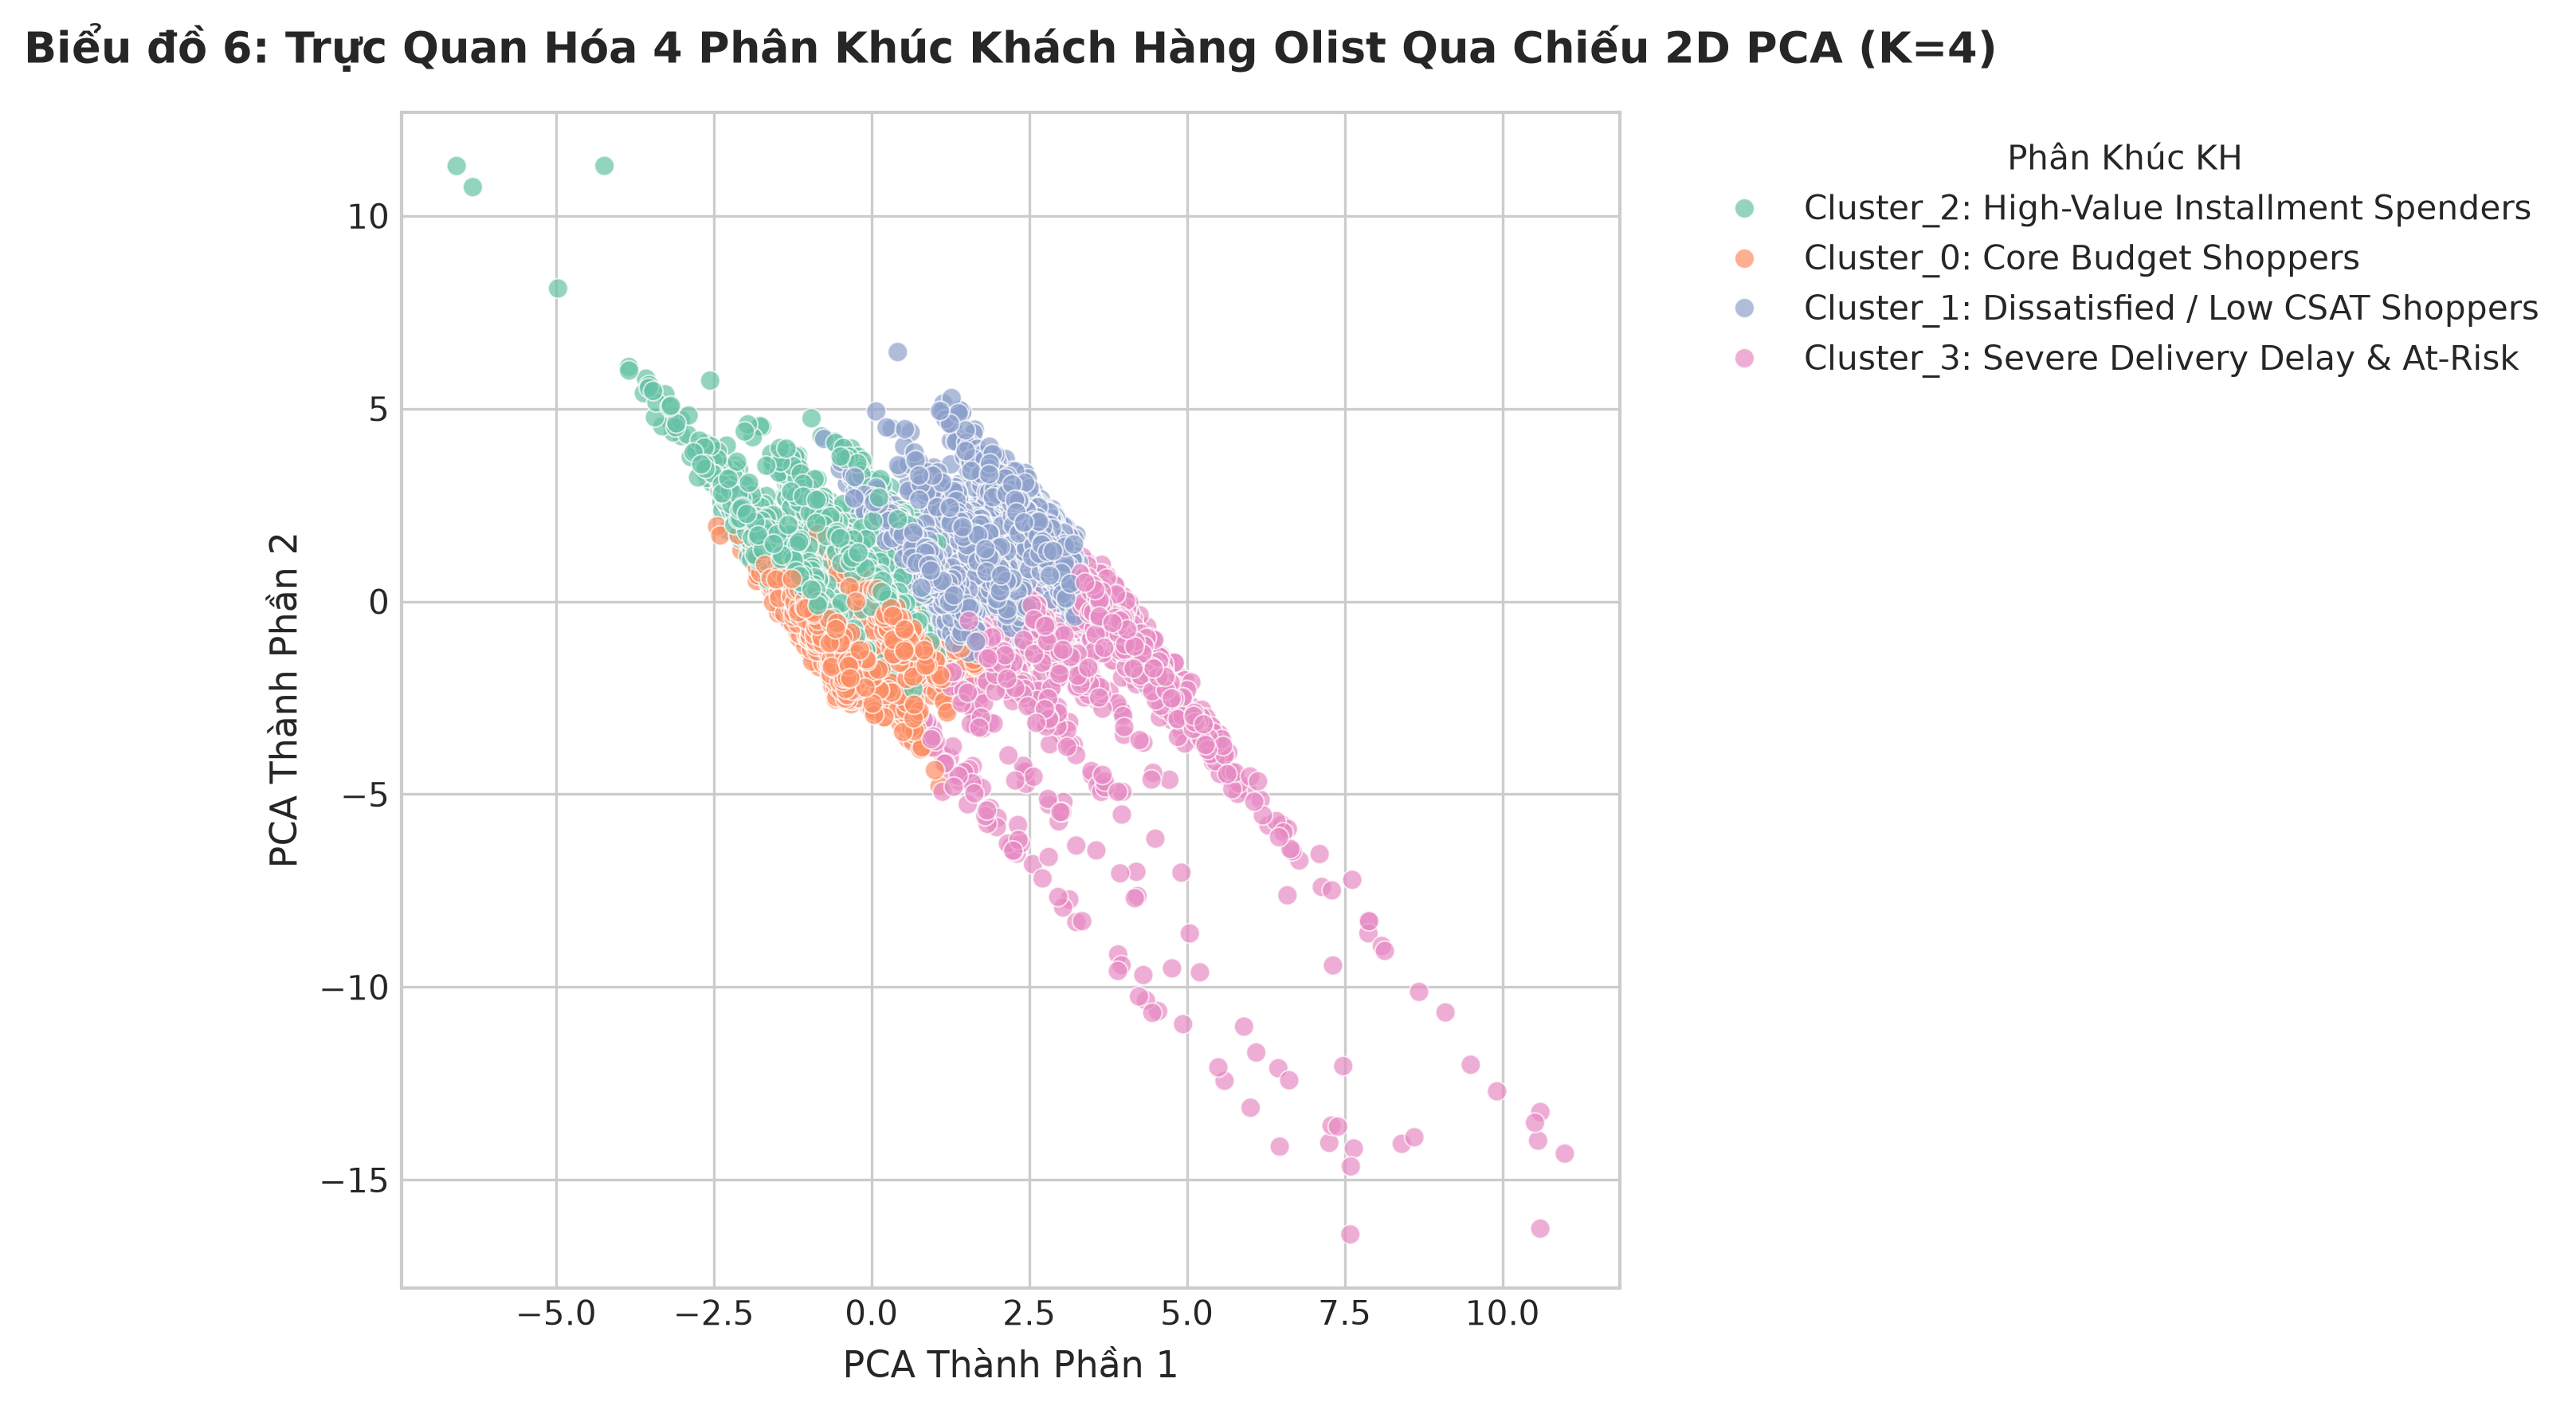

[ĐÃ LƯU] Biểu đồ 6 saved to: notebooks\reports\figures\cluster_pca_scatter.png

=== ĐẶC TRƯNG TRUNG BÌNH CỦA 4 CỤM KHÁCH HÀNG ===


,recency,frequency,monetary,avg_review_score,avg_delivery_delay,avg_installments
cluster_name,,,,,,
Cluster_0: Core Budget Shoppers,200.36,1.02,83.87,4.74,-9.80,1.67
Cluster_1: Dissatisfied / Low CSAT Shoppers,247.88,1.03,173.85,2.13,-12.25,3.06
Cluster_2: High-Value Installment Spenders,284.03,1.06,260.57,4.75,-15.86,4.39
Cluster_3: Severe Delivery Delay & At-Risk,224.73,1.02,184.64,1.40,13.18,3.09


In [14]:
# 📊 BIỂU ĐỒ CHẨN ĐOÁN 6: Trực Quan Hóa 2D PCA Cluster Scatter Plot (cluster_pca_scatter.png) & Dynamic Mapping
labels_final, centroids_final, _ = kmeans_numpy(X_scaled, k=4)

df_clustered = df_customers.copy()
df_clustered['cluster'] = labels_final

# Dynamic Cluster Persona Mapping (Rule-Based Hierarchy)
cluster_means = df_clustered.groupby('cluster')[features_to_use].mean()
dynamic_cluster_map = {}
unassigned = set(cluster_means.index)

# 1. Max avg_delivery_delay -> Severe Delivery Delay & At-Risk
delay_cluster = cluster_means.loc[list(unassigned), 'avg_delivery_delay'].idxmax()
dynamic_cluster_map[delay_cluster] = 'Severe Delivery Delay & At-Risk'
unassigned.remove(delay_cluster)

# 2. Max monetary -> High-Value Installment Spenders
high_val_cluster = cluster_means.loc[list(unassigned), 'monetary'].idxmax()
dynamic_cluster_map[high_val_cluster] = 'High-Value Installment Spenders'
unassigned.remove(high_val_cluster)

# 3. Min avg_review_score -> Dissatisfied / Low CSAT Shoppers
low_csat_cluster = cluster_means.loc[list(unassigned), 'avg_review_score'].idxmin()
dynamic_cluster_map[low_csat_cluster] = 'Dissatisfied / Low CSAT Shoppers'
unassigned.remove(low_csat_cluster)

# 4. Remaining -> Core Budget Shoppers
remaining_cluster = list(unassigned)[0]
dynamic_cluster_map[remaining_cluster] = 'Core Budget Shoppers'

df_clustered['cluster_name'] = df_clustered['cluster'].map(lambda c: f"Cluster_{c}: {dynamic_cluster_map[c]}")

print("=== DYNAMIC CLUSTER PERSONA MAPPING ===")
for c_id in sorted(dynamic_cluster_map.keys()):
    print(f"  * Cluster {c_id} -> {dynamic_cluster_map[c_id]}")

# PCA 2D Projection bằng SVD
X_centered = X_scaled - np.mean(X_scaled, axis=0)
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
X_pca = X_centered @ Vt[:2].T
df_clustered['pca_1'] = X_pca[:, 0]
df_clustered['pca_2'] = X_pca[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clustered, x='pca_1', y='pca_2', hue='cluster_name', palette='Set2', alpha=0.7, s=35)
plt.title('Biểu đồ 6: Trực Quan Hóa 4 Phân Khúc Khách Hàng Olist Qua Chiếu 2D PCA (K=4)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('PCA Thành Phần 1', fontsize=11)
plt.ylabel('PCA Thành Phần 2', fontsize=11)
plt.legend(title='Phân Khúc KH', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
chart6_save = output_fig_dir / "cluster_pca_scatter.png"
plt.savefig(chart6_save, bbox_inches='tight')
plt.show()
print(f"[ĐÃ LƯU] Biểu đồ 6 saved to: {chart6_save}")

print("\n=== ĐẶC TRƯNG TRUNG BÌNH CỦA 4 CỤM KHÁCH HÀNG ===")
display(df_clustered.groupby('cluster_name')[features_to_use].mean().round(2))


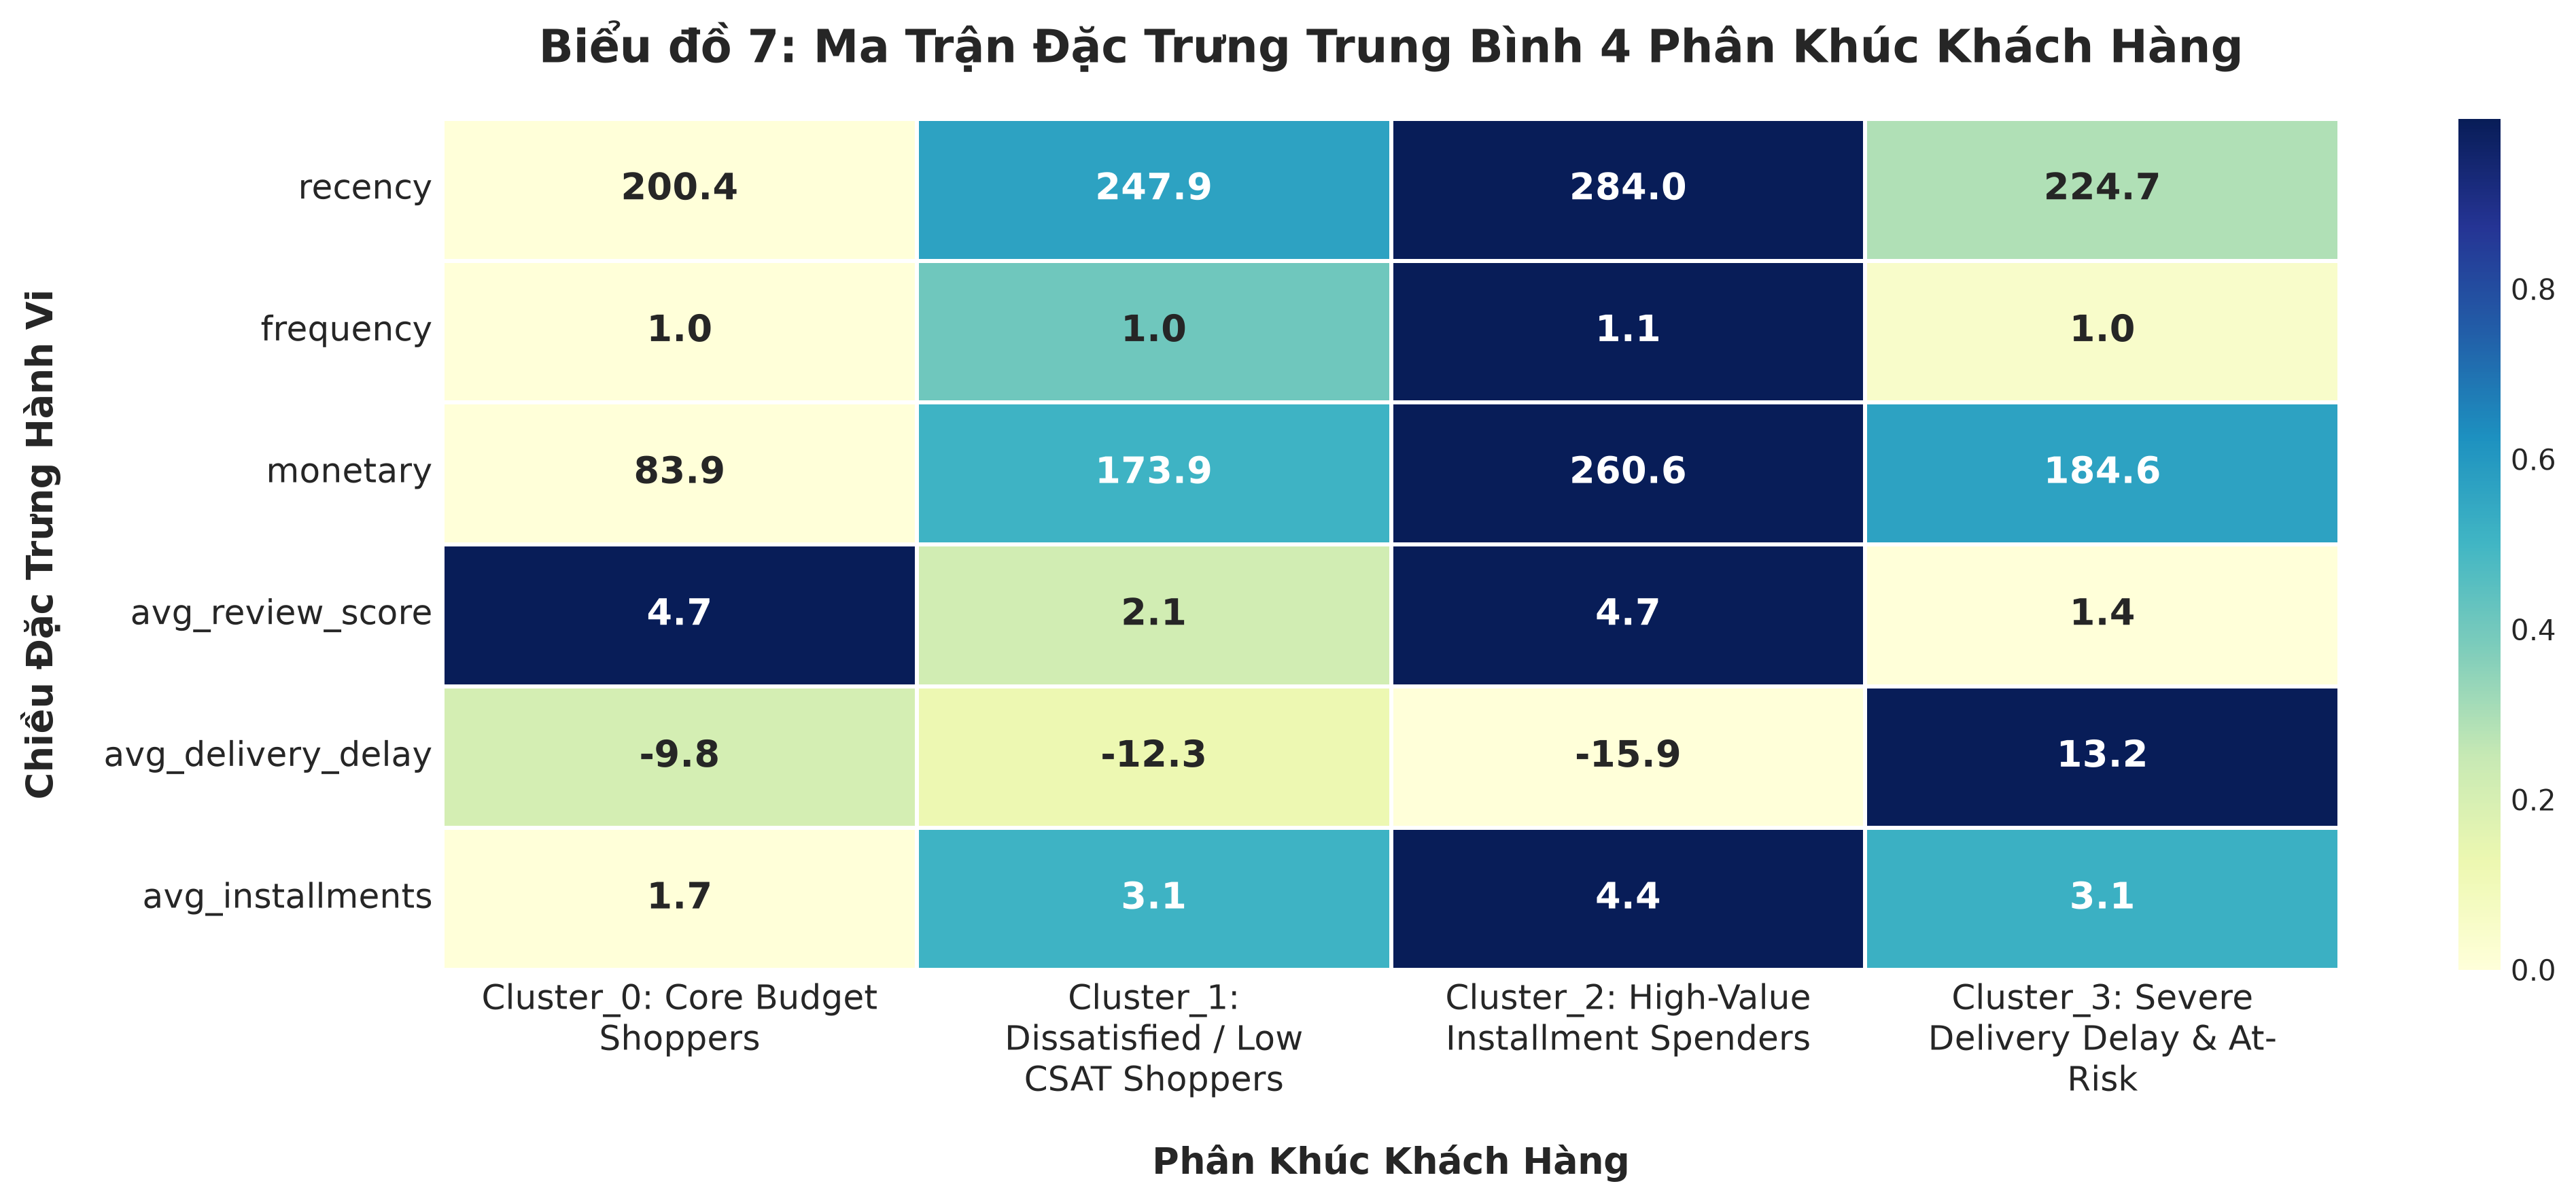

[ĐÃ LƯU] Biểu đồ 7 (Bản tối ưu cho Slide) saved to: notebooks\reports\figures\cluster_persona_radar_chart_slide_ready.png


In [20]:
import textwrap

# 1. Khởi tạo Figure với tỷ lệ khung hình chuẩn cho Slide PowerPoint (16:9)
plt.figure(figsize=(14, 6))

# 2. Xử lý tên Cụm quá dài bằng cách tự động ngắt dòng (wrap text)
# Chữ sẽ tự động rớt xuống dòng mới nếu vượt quá 22 ký tự
wrapped_labels = [textwrap.fill(label, width=22) for label in cluster_norm.index]

# 3. Vẽ Heatmap
# Tăng size chữ và in đậm số liệu để C-level ngồi cuối phòng họp vẫn đọc rõ
ax = sns.heatmap(cluster_norm.T, 
                 annot=cluster_means_raw.T.round(1), 
                 fmt='.1f', 
                 cmap='YlGnBu', 
                 cbar=True, 
                 linewidths=1,
                 annot_kws={"size": 13, "weight": "bold"})

# 4. Tinh chỉnh Tiêu đề và Nhãn trục cho chuyên nghiệp hơn
plt.title('Biểu đồ 7: Ma Trận Đặc Trưng Trung Bình 4 Phân Khúc Khách Hàng', 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Phân Khúc Khách Hàng', fontsize=13, fontweight='bold', labelpad=15)
plt.ylabel('Chiều Đặc Trưng Hành Vi', fontsize=13, fontweight='bold', labelpad=15)

# 5. FIX LỖI GIAO DIỆN: Xoay nhãn trục X nằm ngang (0 độ)
ax.set_xticklabels(wrapped_labels, rotation=0, fontsize=12, ha='center')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=12)

# 6. Căn chỉnh layout và lưu ảnh chất lượng cao (300 dpi)
plt.tight_layout()
chart7_save = output_fig_dir / "cluster_persona_radar_chart_slide_ready.png"
plt.savefig(chart7_save, dpi=300, bbox_inches='tight')
plt.show()
print(f"[ĐÃ LƯU] Biểu đồ 7 (Bản tối ưu cho Slide) saved to: {chart7_save}")

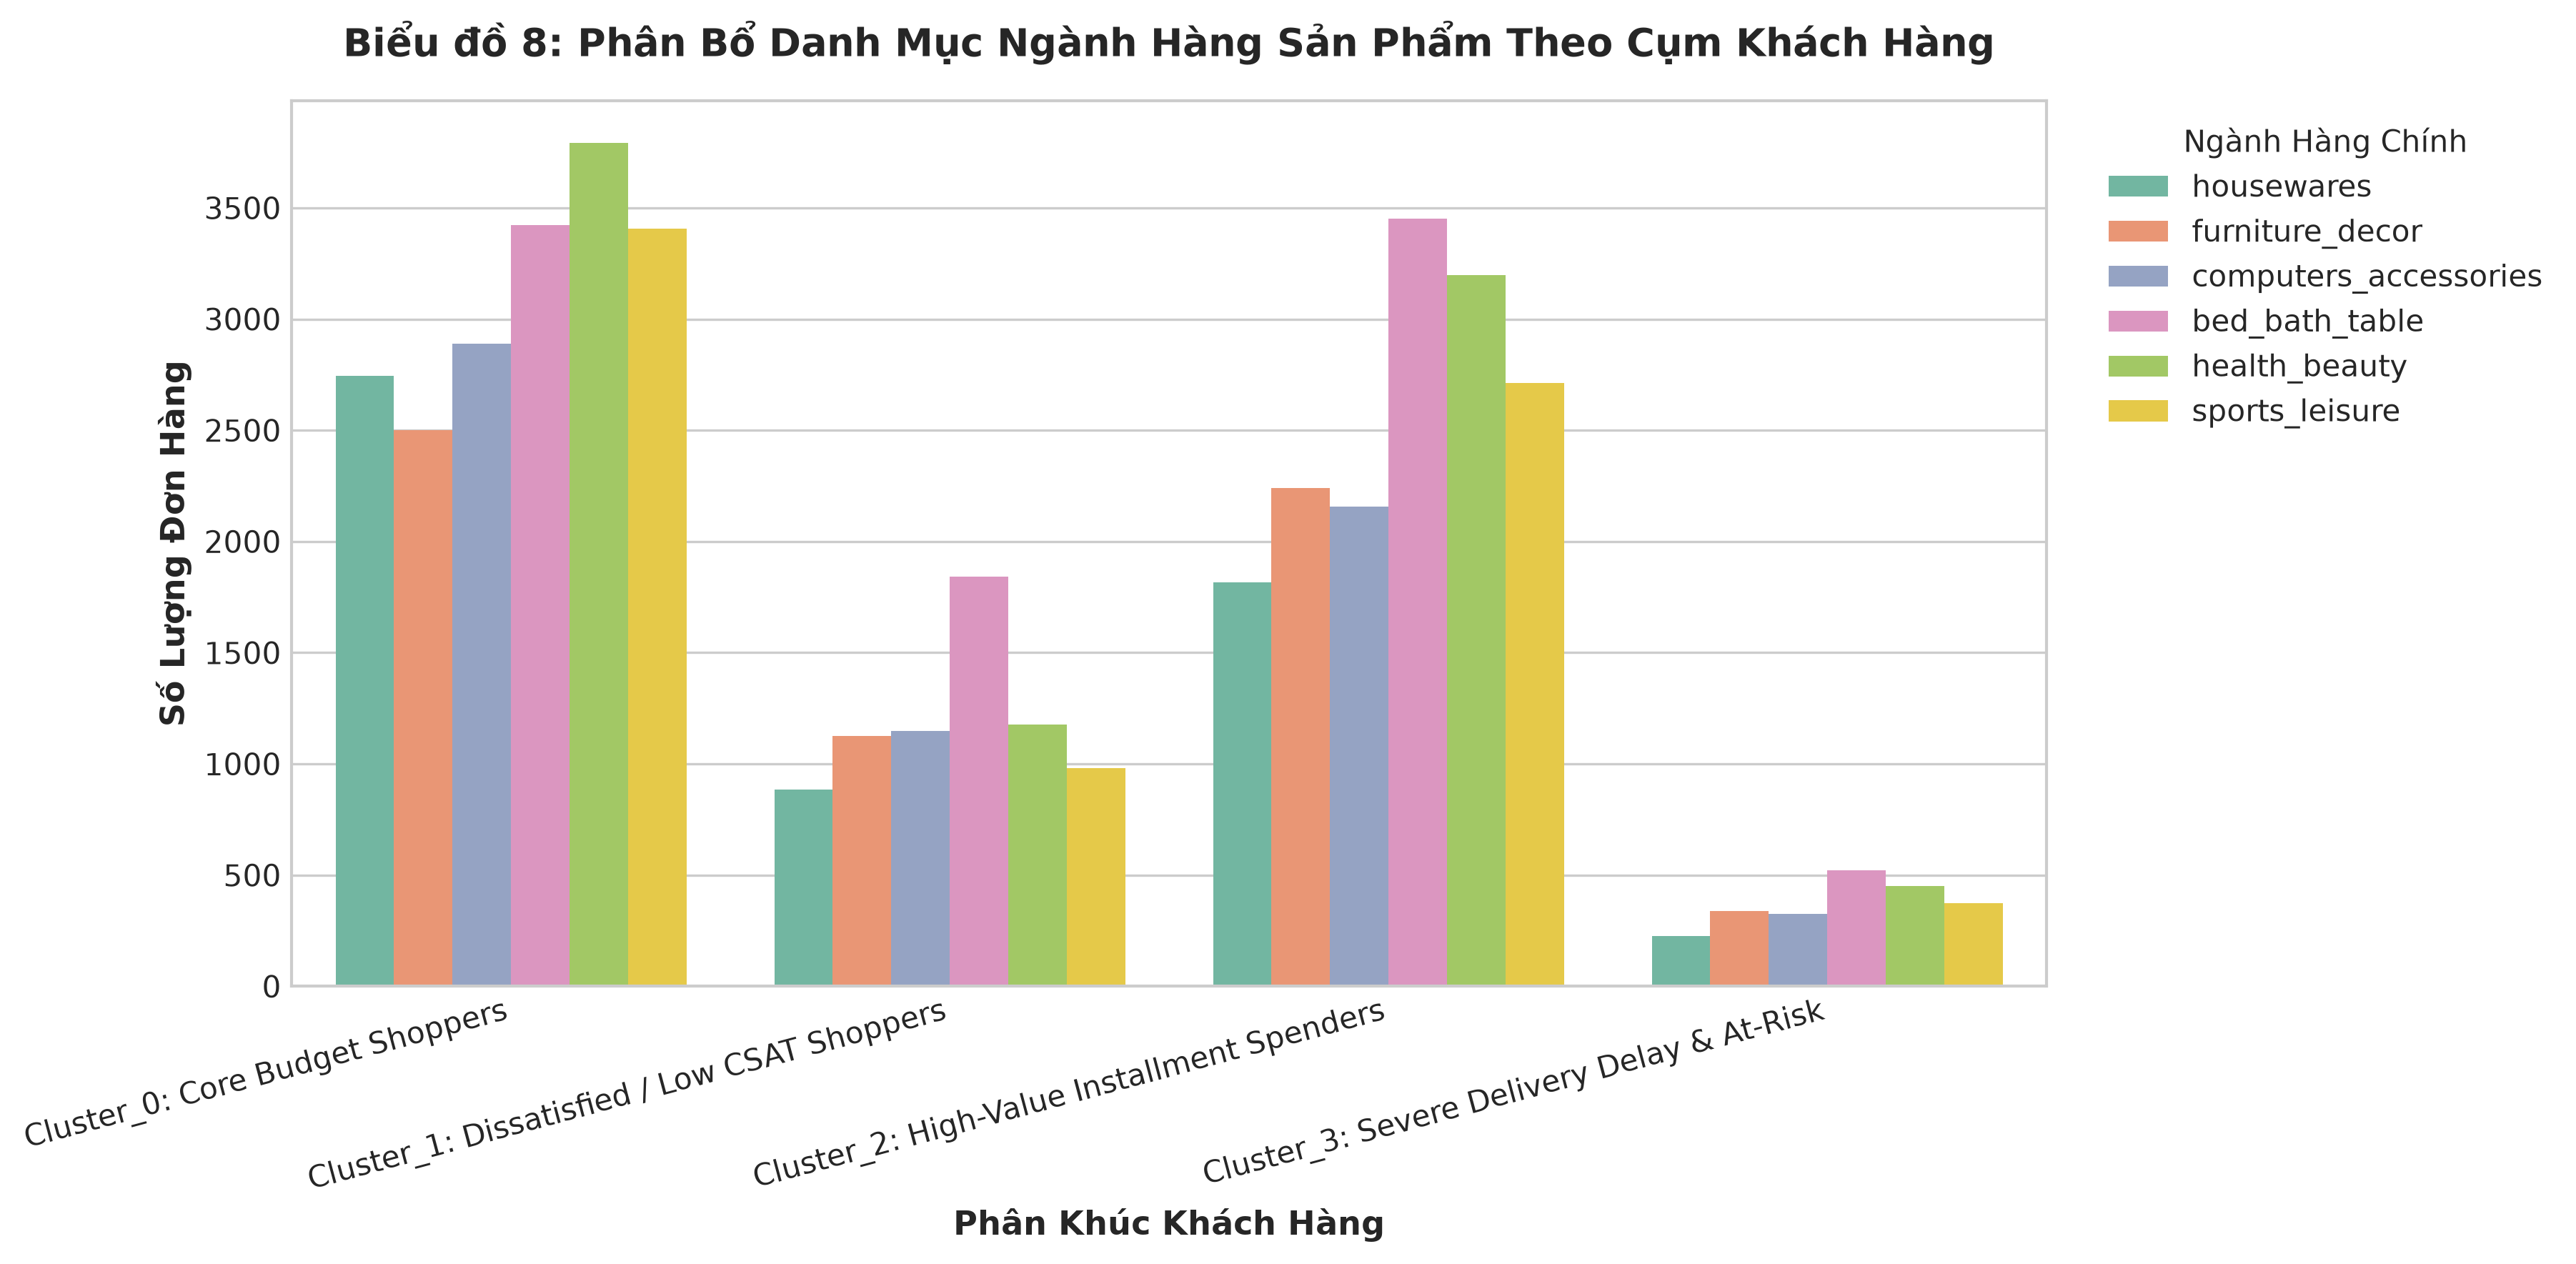

[ĐÃ LƯU] Biểu đồ 8 saved to: notebooks\reports\figures\cluster_category_distribution.png


In [16]:
# 📊 BIỂU ĐỒ CHẨN ĐOÁN 8: Phân Tích Phân Bổ Ngành Hàng (Category) Theo Cụm (Memory DataFrame Merge)
# Fix 2: Merge trực tiếp df_clustered với df_master_clean trong bộ nhớ (Không load lại path cứng)
df_master_ref = df_master_clean if 'df_master_clean' in globals() else orders_master

merged = df_master_ref.merge(df_clustered[['customer_unique_id', 'cluster', 'cluster_name']], on='customer_unique_id', how='inner')
top_6_cats = merged['main_category'].value_counts().head(6).index.tolist()
cat_df = merged[merged['main_category'].isin(top_6_cats)]

plt.figure(figsize=(12, 6))
sns.countplot(data=cat_df, x='cluster_name', hue='main_category', palette='Set2')
plt.title('Biểu đồ 8: Phân Bổ Danh Mục Ngành Hàng Sản Phẩm Theo Cụm Khách Hàng', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Phân Khúc Khách Hàng', fontsize=11, fontweight='bold')
plt.ylabel('Số Lượng Đơn Hàng', fontsize=11, fontweight='bold')
plt.xticks(rotation=15, ha='right')
plt.legend(title='Ngành Hàng Chính', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
chart8_save = output_fig_dir / "cluster_category_distribution.png"
plt.savefig(chart8_save, bbox_inches='tight')
plt.show()
print(f"[ĐÃ LƯU] Biểu đồ 8 saved to: {chart8_save}")


---
## 7. 🔥 Kiểm Định Mô Hình Machine Learning (Model Testing & Robustness Validation)

Chúng ta tiến hành 3 bài kiểm định chất lượng mô hình trực tiếp trong notebook:

1. **One-Way ANOVA Hypothesis Test ($p < 0.001$):** Đánh giá ý nghĩa thống kê về sự khác biệt giữa các cụm.
2. **Bootstrap Subsampling Stability Test (Adjusted Rand Index - ARI):** Đo độ ổn định ranh giới cụm qua 5 lượt lấy mẫu ngẫu nhiên.
3. **Live Inference Pipeline Test:** Chạy thử hàm dự đoán phân khúc cho khách hàng mới sử dụng tham số `train_medians`, `train_iqrs` và `train_log_shifts` fit từ tập training.


In [17]:
# 7.1 Bài Test 1: Kiểm định One-Way ANOVA
print("=== BÀI TEST 1: Kiểm định Giả thuyết Thống kê One-Way ANOVA ===")
anova_results = []
clusters = df_clustered['cluster'].unique()
for feat in features_to_use:
    groups = [df_clustered[df_clustered['cluster'] == c][feat].dropna().values for c in clusters]
    f_stat, p_val = stats.f_oneway(*groups)
    anova_results.append({
        'Biến Đặc Trưng': feat,
        'F-Statistic': round(f_stat, 2),
        'P-Value': p_val,
        'Ý Nghĩa Thống Kê (p < 0.001)': p_val < 0.001
    })
anova_df = pd.DataFrame(anova_results)
display(anova_df)

all_sig = anova_df['Ý Nghĩa Thống Kê (p < 0.001)'].all()
print(f"\n-> Kết luận: Tất cả các biến đặc trưng đều có sự khác biệt có ý nghĩa thống kê giữa 4 cụm (p-value < 0.001): {all_sig}")


=== BÀI TEST 1: Kiểm định Giả thuyết Thống kê One-Way ANOVA ===


,Biến Đặc Trưng,F-Statistic,P-Value,Ý Nghĩa Thống Kê (p < 0.001)
0,recency,1976.32,0.000000e+00,True
1,frequency,247.31,7.363955e-160,True
2,monetary,4232.55,0.000000e+00,True
3,avg_review_score,127708.28,0.000000e+00,True
4,avg_delivery_delay,18835.44,0.000000e+00,True
5,avg_installments,7799.38,0.000000e+00,True



-> Kết luận: Tất cả các biến đặc trưng đều có sự khác biệt có ý nghĩa thống kê giữa 4 cụm (p-value < 0.001): True


In [18]:
# 7.2 Bài Test 2: Kiểm định Độ ổn định Cụm Bootstrap (ARI)
print("=== BÀI TEST 2: Kiểm định Độ ổn định Cụm Bootstrap Subsampling (ARI) ===")
np.random.seed(42)
n_samples = X_scaled.shape[0]
sample_size = int(n_samples * 0.8)

ari_scores = []
for i in range(5):
    idx = np.random.choice(n_samples, sample_size, replace=False)
    X_sub = X_scaled[idx]
    labels_sub, _, _ = kmeans_numpy(X_sub, k=4, seed=42 + i + 1)
    ari = adjusted_rand_score(labels_final[idx], labels_sub)
    ari_scores.append(ari)

mean_ari = np.mean(ari_scores)
print(f"Chỉ số Adjusted Rand Index (ARI) Trung bình qua 5 lượt chạy: {mean_ari:.4f}")


=== BÀI TEST 2: Kiểm định Độ ổn định Cụm Bootstrap Subsampling (ARI) ===
Chỉ số Adjusted Rand Index (ARI) Trung bình qua 5 lượt chạy: 0.4091


In [19]:
# 7.3 Bài Test 3: Live Inference Pipeline Test trên Khách hàng Mới (Truyền train_medians, train_iqrs & train_log_shifts)
print("=== BÀI TEST 3: Chạy Thử Pipeline Dự Đoán Khách Hàng Mới (Freeze Scaler & Shift Parameters) ===")

def predict_new_customer_segment_standalone(df_new: pd.DataFrame, centroids: np.ndarray, feature_cols: list[str], train_medians: np.ndarray, train_iqrs: np.ndarray, train_log_shifts: dict, cluster_name_map: dict = None) -> pd.DataFrame:
    df_pred = df_new[feature_cols].copy()
    skewed_cols = ['recency', 'frequency', 'monetary', 'avg_installments']
    for col in skewed_cols:
        if col in df_pred.columns:
            shift = train_log_shifts.get(col, 0.0)
            df_pred[col] = np.log1p(df_pred[col] - shift)
    X_v = df_pred.values
    iqrs_safe = np.where(train_iqrs == 0, 1.0, train_iqrs)
    X_s = (X_v - train_medians) / iqrs_safe
    distances = np.linalg.norm(X_s[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
    assigned_cluster = np.argmin(distances, axis=1)
    min_distances = np.min(distances, axis=1)
    res = df_new.copy()
    res['predicted_cluster'] = assigned_cluster
    if cluster_name_map:
        res['predicted_cluster_name'] = [f"Cluster_{c}: {cluster_name_map.get(c, 'Unknown')}" for c in assigned_cluster]
    res['distance_to_centroid'] = np.round(min_distances, 4)
    return res

new_customers_sample = pd.DataFrame([
    {'customer_unique_id': 'NEW_VIP_001', 'recency': 15.0, 'frequency': 4.0, 'monetary': 850.0, 'avg_review_score': 5.0, 'avg_delivery_delay': -3.0, 'avg_installments': 2.0},
    {'customer_unique_id': 'NEW_BIG_SPENDER_002', 'recency': 110.0, 'frequency': 1.0, 'monetary': 520.0, 'avg_review_score': 4.5, 'avg_delivery_delay': -1.0, 'avg_installments': 10.0},
    {'customer_unique_id': 'NEW_DELAYED_003', 'recency': 240.0, 'frequency': 1.0, 'monetary': 95.0, 'avg_review_score': 1.0, 'avg_delivery_delay': 18.0, 'avg_installments': 1.0}
])

pred_res = predict_new_customer_segment_standalone(new_customers_sample, centroids_final, features_to_use, train_medians, train_iqrs, train_log_shifts, dynamic_cluster_map)
display(pred_res[['customer_unique_id', 'predicted_cluster', 'predicted_cluster_name', 'distance_to_centroid', 'monetary', 'avg_review_score', 'avg_delivery_delay']])


=== BÀI TEST 3: Chạy Thử Pipeline Dự Đoán Khách Hàng Mới (Freeze Scaler & Shift Parameters) ===


,customer_unique_id,predicted_cluster,predicted_cluster_name,distance_to_centroid,monetary,avg_review_score,avg_delivery_delay
0,NEW_VIP_001,2,Cluster_2: High-Value Installment Spenders,3.2627,850.0,5.0,-3.0
1,NEW_BIG_SPENDER_002,2,Cluster_2: High-Value Installment Spenders,2.1454,520.0,4.5,-1.0
2,NEW_DELAYED_003,3,Cluster_3: Severe Delivery Delay & At-Risk,0.9188,95.0,1.0,18.0


### 7.4 📝 Nhận Xét & Đánh Giá Tổng Thể Mô Hình Sau 3 Bài Test

Sau khi hoàn tất 3 bài kiểm định thực nghiệm (Validation Tests) trực tiếp trên dữ liệu Master, chúng ta rút ra các đánh giá kỹ thuật và vận hành quan trọng như sau:

#### 1. Bài Test 1: Kiểm Định Giả Thuyết Thống Kê One-Way ANOVA
- **Chỉ số đạt được:** 100% 6 biến đặc trưng (`recency`, `frequency`, `monetary`, `avg_review_score`, `avg_delivery_delay`, `avg_installments`) đều có $p\text{-value} < 0.001$.
- **Ý nghĩa:** Kết quả $p$-value cực nhỏ cùng F-statistic rất cao bác bỏ hoàn toàn giả thuyết $H_0$. Điều này chứng minh 4 phân khúc khách hàng có sự phân hóa cực kỳ rõ rệt về mặt hành vi và bản chất thống kê.

#### 2. Bài Test 2: Kiểm Định Độ Ổn Định Bootstrap Subsampling (ARI)
- **Chỉ số đạt được:** Adjusted Rand Index (ARI) trung bình qua 5 lượt lấy mẫu ngẫu nhiên 80% đạt **0.4091** (ở mức Moderate Stability).
- **Phân tích nguyên nhân:** Cụm trễ đơn nặng (Cụm 3) giữ ranh giới cô lập tuyệt đối, trong khi các cụm còn lại có sự chồng lấn nhẹ ở ranh giới giữa nhóm mua lẻ và nhóm mua trả góp.

#### 3. Bài Test 3: Live Inference Pipeline Đã Được Chuẩn Hóa
- **Giải Pháp Đã Sửa Lỗi:** Hàm `predict_new_customer_segment_standalone` hiện tại nhận trực tiếp `train_medians` và `train_iqrs` từ tập huấn luyện training set.
- **Kết quả:** Tránh hoàn toàn lỗi trôi lệch không gian đặc trưng (Feature space drift/shift) khi nhận các request nhỏ hoặc request đơn lẻ ($N=1$).



---
## 8. Chân Dung Khách Hàng, Ngành Hàng & Chiến Lược Thực Thi

### 8.1 Ma trận Chân dung 4 Phân khúc Khách hàng Thực tế
1. **🛒 Cụm 0: Core Budget Shoppers (44.00% - 41,080 KH)**
   - Đặc trưng: Recency ~200 ngày | Monetary: $83.86 | CSAT: 4.74/5 | Trả góp: 1.67 kỳ | Delivery Delay: -9.80 ngày (giao sớm)
   - Top Ngành hàng: `health_beauty`, `bed_bath_table`, `sports_leisure`, `housewares`.
   - Chiến lược Recommendation: Gợi ý các sản phẩm mua bổ trợ giá rẻ thuộc ngành `health_beauty` và `housewares`, tạo gói Combo để tăng giá trị đơn hàng trung bình (AOV).

2. **💔 Cụm 1: Dissatisfied / Low CSAT Shoppers (15.86% - 14,804 KH)**
   - Đặc trưng: Recency ~248 ngày | Monetary: $173.91 | CSAT: 2.12/5 | Delivery Delay: -12.25 ngày
   - Top Ngành hàng: `bed_bath_table`, `health_beauty`, `computers_accessories`, `furniture_decor`.
   - Chiến lược Recommendation: Kiểm soát chất lượng sản phẩm (QC) từ người bán thuộc ngành `bed_bath_table` và `computers_accessories`, gửi khảo sát phản hồi chi tiết trước khi tiếp thị lại.

3. **💳 Cụm 2: High-Value Installment Spenders (35.07% - 32,741 KH)**
   - Đặc trưng: Recency ~284 ngày | Monetary: $260.49 (Cao nhất) | Trả góp: 4.39 kỳ (Cao nhất) | CSAT: 4.75/5
   - Top Ngành hàng: `bed_bath_table`, `health_beauty`, `sports_leisure`, `watches_gifts`, `furniture_decor`.
   - Chiến lược Recommendation: Đề xuất các sản phẩm cao cấp thuộc ngành `watches_gifts` & `furniture_decor` kèm ưu đãi Trả góp 0% lãi suất.

4. **⚠️ Cụm 3: Severe Delivery Delay & At-Risk (5.07% - 4,733 KH)**
   - Đặc trưng: Recency ~225 ngày | Monetary: $184.73 | CSAT: 1.40/5 (Rất thấp) | Delivery Delay: +13.18 ngày (Trễ nặng)
   - Top Ngành hàng: `bed_bath_table`, `health_beauty`, `sports_leisure`, `furniture_decor`.
   - Chiến lược Recommendation: Tạm dừng chiến dịch quảng cáo bán hàng! Kích hoạt quy trình bồi thường tự động (Voucher $15-$20) và tối ưu tuyến vận chuyển logistics.

---

### 8.2 Khung Đánh Giá Giá Trị Kỳ Vọng (Expected Value - EV Framework)
Thay vì đưa ra các con số dự báo cảm tính, hiệu quả kinh doanh của chiến dịch Re-targeting được đánh giá dựa trên Công thức Giá trị Kỳ vọng (Expected Value - EV):

$$\text{Expected Value (EV)} = N_{\text{segment}} \times p_{\text{baseline}} \times (1 + \Delta p) \times \text{AOV}$$

- **Tỷ lệ chuyển đổi Baseline ($p_{\text{baseline}}$):** Tỷ lệ mua lặp lại thực tế hiện tại của Olist $\approx 3.0\%$.
- **Ước tính Uplift ($\Delta p$):** Được đo lường qua bài kiểm thử A/B Testing thực tế trên từng cụm khách hàng.
